# Thrombolysis and thrombectomy in non-mild stroke arriving within 6 hours: doubly robust causal forest

## Summary

**Aim.** To estimate the effect of seven intravenous thrombolysis (IVT) and mechanical thrombectomy (MT) strategies, defined by the treatment given and how soon after onset, on a good outcome at hospital discharge in patients with non-mild ischaemic stroke who arrive within 6 hours of onset, and how that effect varies between patients.

**Data.** SSNAP stroke admissions in England and Wales, 2020–2025 (cleaned data). 74,611 patients with complete data are analysed, from stroke teams that gave at least 10 thrombectomies in the cohort; 37,602 received neither treatment.

**Method.** A causal forest within a double machine learning framework (CausalForestDML, EconML). Cross-fitted LightGBM models predict the outcome and each patient's probability of each treatment strategy from baseline characteristics, comorbidities, ethnicity, stroke team and year; a forest of 2,000 honest trees then estimates each patient's treatment effect. The main estimate is the doubly robust (AIPW) average effect in the treated (ATT): the difference in the probability of a good outcome (discharge mRS 0–2, or no worse than pre-stroke mRS) for each strategy compared with neither.

**Main results.**

* The first-stage models perform well (outcome AUC 0.753; treatment AUCs 0.679 to 0.906), and overlap is good: fewer than 1% of patients in any treated group have P(neither) < 0.05.
* Every strategy is associated with a higher probability of a good outcome in the patients who received it. ATTs range from **+8.5 percentage points** (late IVT only, 95% CI 5.7 to 11.2; late MT only, 6.3 to 10.8) to **+23.7** (early IVT plus early MT; 21.2 to 26.2). All 95% CIs exclude zero.
* Earlier treatment is associated with larger effects: IVT only +13.1 early vs +8.5 late; MT only +17.6 early vs +8.5 late; after early IVT, early MT +23.7 vs late MT +12.0.
* Relative effects (risk ratios in the treated) range from 1.22 to 2.05.
* The estimates are robust to model settings, random seeds, overlap trimming and the early/late cut-off. They are more sensitive to which confounders are adjusted for: additionally adjusting for onset-to-scan time lowers the early-strategy ATTs by 3 to 9 points (early both 15.2), and adjusting for LVO raises the MT estimates.
* E-values range from 1.74 to 3.51. A confounder as strong as NIHSS, or leaving NIHSS out of the model, removes most of the MT-based effects but not the IVT-alone effects.

**Conclusion.** After doubly robust adjustment, every IVT and MT strategy is associated with a gain of about 8 to 24 percentage points in good outcome at discharge, largest for early treatment and especially early MT. The IVT-alone results are robust; the MT-based results depend heavily on adjustment for stroke severity, and the size of the early-strategy effects depends on whether onset-to-scan time is treated as a confounder.

## Method overview

To estimate how the effect of thrombolysis and thrombectomy varied between patients, we used a causal forest estimated within a double machine learning framework (CausalForestDML, EconML). In clinical terms, the method asks: for patients who look alike, did those who received thrombolysis do better than we would have expected them to? It works in two stages.

In the first stage, two prediction models were built with gradient-boosted decision trees (LightGBM). The first predicted each patient's probability of a good outcome from their baseline characteristics and stroke team, without knowing the treatment given. These characteristics were age, stroke severity, pre-stroke disability, comorbidities, atrial fibrillation and anticoagulation status, and ethnicity. The second predicted the probability of each of the eight treatment groups (neither, or thrombolysis and/or thrombectomy, each early or late) from the same information. It therefore captures the clinical and organisational factors that influence who is treated.

The models used five-fold cross-fitting, so each patient's predictions came from models trained on other patients. Subtracting the predictions from what actually happened left two residuals: how much better or worse each patient's outcome was than expected, and how far their treatment differed from what would typically be given to someone like them. Removing the predictable part of both treatment and outcome adjusts for measured confounding, including confounding by indication. A further advantage is that small errors in either prediction model have only a limited, second-order effect on the final estimates.

In the second stage, a forest of 2,000 "honest" trees related the outcome residuals to the treatment residuals. Each tree used one half of its data to choose how to split patients into subgroups and the other half to estimate the treatment effect within them, which reduces overfitting. The result was an estimated absolute change in the probability of a good outcome for each patient under each treatment strategy compared with neither treatment. These estimates were then summarised by treatment window and by patient characteristics.

As with any observational analysis, the estimates assume there is no important unmeasured confounding, and that comparable patients were found in both the treated and untreated groups.

![](./images/dml_causal_forest_thrombolysis_method.png)

## What this notebook estimates

Each patient is in one of eight treatment groups ("neither", or thrombolysis and/or thrombectomy, each early or late; early = thrombolysis within 270 min or thrombectomy before 270 min). The causal forest estimates, for each treatment strategy compared with neither:

| Estimate | Meaning | How it is calculated |
|---|---|---|
| **ATT** (main result) | Average effect in patients who actually received that strategy | Doubly robust (augmented inverse-probability-weighted, AIPW) estimate from the cross-fitted first-stage models and the forest, with 95% CI |
| **ATE** | Average effect if *everyone* in the cohort received that strategy | AIPW estimate over all patients, with 95% CI. Only reported where positivity holds for most of the cohort |
| **Mean CATE in treated** | Simple average of the forest's individual-level (conditional) effect estimates in patients who received that strategy | Plug-in average (no CI) |

The ATT is the most relevant estimate. The ATE extrapolates each treatment to patients who would rarely receive it (for example thrombectomy for patients unlikely to have a large vessel occlusion), so it relies more on the model.

### Notebook structure

1. Set-up: modules, settings, features
2. Cohort selection, treatment groups and patient flow
3. Descriptive statistics
4. Model definition and fitting
5. Model diagnostics: first-stage performance and overlap
6. Treatment effects (ATT, ATE, mean CATE)
7. Heterogeneity of effects
8. Relative effects, first-stage performance and a test of heterogeneity
9. Sensitivity analyses: analytic choices, E-values, sensemakr, leave-one-out
10. Observed outcomes by treatment strategy
11. Conclusions and limitations

# 1. Set-up

## Load modules

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from econml.dml import CausalForestDML  # causal forest within double machine learning
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score
import statsmodels as sm

warnings.filterwarnings('ignore')

## Settings

All analysis choices are set here; the sensitivity analyses change one at a time.

* **Good outcome:** discharge mRS ≤ 2 (`MRS_TARGET`), or no worse than pre-stroke mRS.
* **Early/late cut-off:** 270 minutes (`CUTOFF`); 99,999 minutes means "treatment not given".
* **First-stage models:** LightGBM with 400 trees, 31 leaves, learning rate 0.03 and 80% row and column subsampling (`NUISANCE_PARAMS`), with 5 cross-fitting folds (`CV_FOLDS`).
* **AIPW:** treatment probabilities are clipped at 0.01 (`PROPENSITY_CLIP`); the ATE is reported only if fewer than 20% of patients fall below the clip (`ATE_MAX_CLIPPED_PCT`).
* **Forest:** number of trees and minimum leaf size (`N_TREES`, `MIN_SAMPLES_LEAF`), and a fixed random seed.

In [2]:
prefix = "non_mild_stroke_early_arrival_good_outcome_causal_forest"
DATA_PATH = "../data/sam3/cleaned_data.csv"
OUTPUT_DIR = "./output"

MRS_TARGET = 2          # good outcome: discharge mRS <= MRS_TARGET, or no worse than pre-stroke mRS
CUTOFF = 270            # minutes from onset separating early from late treatment
NO_TREATMENT = 99999    # sentinel time meaning "treatment not given"
SEED = 42

# First-stage (nuisance) models: LightGBM gradient-boosted trees
NUISANCE_PARAMS = dict(n_estimators=400, num_leaves=31, learning_rate=0.03,
                       subsample=0.8, colsample_bytree=0.8, n_jobs=-1, verbosity=-1)
CV_FOLDS = 5            # cross-fitting folds
PROPENSITY_CLIP = 0.01  # lower limit for treatment probabilities in the AIPW estimates
ATE_MAX_CLIPPED_PCT = 20  # report ATE only if fewer than this % of patients have P(strategy) < PROPENSITY_CLIP

# Second stage: causal forest
N_TREES = 2000
MIN_SAMPLES_LEAF = 25

TIME_THROMBOLYSIS = "onset_to_thrombolysis_time"
TIME_THROMBECTOMY = "onset_to_thrombectomy_time"

## Define features

* **X (effect modifiers):** pre-treatment clinical features that the effect of treatment may vary with: pre-stroke disability, stroke severity, age, congestive heart failure, hypertension, diabetes, AF anticoagulant use, any AF diagnosis and ethnicity. The forest splits on these to find subgroups with different effects.
* **W (confounders):** features adjusted for in the first-stage models but not used for splitting. W contains all of X, plus:
  * stroke team, which captures differences in practice between hospitals
  * year

Onset-to-scan time is not adjusted for in the primary analysis, because it largely determines whether early treatment is possible rather than confounding the treatment–outcome relationship; adjusting for it is a sensitivity analysis.
* **Categorical features** (stroke team, ethnicity) are coded as integers and handled natively by LightGBM.

Treatment groups are numbered so that EconML uses "neither" as the baseline.

In [3]:
X_FEATURES = [
    'prior_disability',
    'stroke_severity',
    'age',
    'congestive_heart_failure',
    'hypertension',
    'diabetes',
    'afib_anticoagulant',
    'any_afib_diagnosis',
    'ethnicity',
]

W_FEATURES = X_FEATURES + [
    'stroke_team',
    'year',
]

CATEGORICAL_FEATURES = ['stroke_team', 'ethnicity']
TREATMENT_TIMES = [TIME_THROMBOLYSIS, TIME_THROMBECTOMY]

# Treatment groups. EconML one-hot encodes a discrete treatment and uses the first level
# (alphabetically) as the baseline, so codes are prefixed with a number to fix the order.
CONTROL_GROUP = "neither"
GROUP_ORDER = [
    'early_thrombolysis_only',
    'late_thrombolysis_only',
    'early_thrombectomy_only',
    'late_thrombectomy_only',
    'early_both',
    'early_thrombolysis_late_thrombectomy',
    'late_both',
]
ARM_CODES = {g: f"{i}_{g}" for i, g in enumerate([CONTROL_GROUP] + GROUP_ORDER)}
BASELINE_ARM = ARM_CODES[CONTROL_GROUP]
GROUP_LABELS = {
    'early_thrombolysis_only': 'Early thrombolysis only',
    'late_thrombolysis_only': 'Late thrombolysis only',
    'early_thrombectomy_only': 'Early thrombectomy only',
    'late_thrombectomy_only': 'Late thrombectomy only',
    'early_both': 'Early both',
    'early_thrombolysis_late_thrombectomy': 'Early thrombolysis,\nlate thrombectomy',
    'late_both': 'Late both',
}

# 2. Cohort selection and treatment groups

Patients are included if they:

* had an ischaemic stroke, arrived within 6 hours of onset, and had a recorded discharge mRS
* had no perfusion imaging
* had NIHSS > 5 or a large vessel occlusion
* were seen by a team that gave at least 10 thrombectomies in the cohort

Records with implausible treatment times are removed (thrombolysis after thrombectomy, thrombectomy 12 hours or more after onset, thrombolysis 6 hours or more after onset). The causal forest needs complete data for every feature, so patients with any missing feature are excluded.

Each patient is assigned to one strategy from their onset-to-treatment times. "Early" means thrombolysis within 270 minutes of onset, or thrombectomy before 270 minutes. A patient with late thrombolysis and thrombectomy at exactly 270 minutes matches none of the treated rules and is labelled "neither".

In [4]:
def assign_treatment_groups(df, cutoff=CUTOFF):
    # Label each patient with a treatment strategy; later rules overwrite earlier ones
    lysis, ect = df[TIME_THROMBOLYSIS], df[TIME_THROMBECTOMY]
    has_lysis, has_ect = lysis != NO_TREATMENT, ect != NO_TREATMENT
    group = pd.Series(CONTROL_GROUP, index=df.index)
    group[(lysis <= cutoff) & ~has_ect] = "early_thrombolysis_only"
    group[(lysis > cutoff) & has_lysis & ~has_ect] = "late_thrombolysis_only"
    group[~has_lysis & (ect < cutoff)] = "early_thrombectomy_only"
    group[~has_lysis & (ect >= cutoff) & has_ect] = "late_thrombectomy_only"
    group[(lysis <= cutoff) & (ect < cutoff)] = "early_both"
    group[(lysis <= cutoff) & (ect >= cutoff) & has_ect] = "early_thrombolysis_late_thrombectomy"
    group[(lysis > cutoff) & has_lysis & (ect > cutoff) & has_ect] = "late_both"
    df["treatment_group"] = group
    return df


def build_cohort(raw, cutoff=CUTOFF, extra_features=(), verbose=False):
    # Apply eligibility criteria, keep model features, drop incomplete rows, add treatment groups.
    # extra_features: additional columns to keep (missing values coded as -1, not dropped).
    df = raw.copy()
    df["onset_to_scan_time"] = df["onset_to_arrival_time"] + df["arrival_to_scan_time"]
    log = [("All records", len(df))]

    def keep_rows(label, mask):
        nonlocal df
        df = df[mask]
        log.append((label, len(df)))

    keep_rows("Discharge mRS recorded", df["discharge_disability"].notna())
    keep_rows("Infarction", df["infarction"] == 1)
    keep_rows("Arrival within 360 min of onset", df["onset_to_arrival_time"] < 360)
    keep_rows("No perfusion imaging", df["perfusion_imaging_used"] == 0)
    keep_rows("NIHSS > 5 or LVO", (df["stroke_severity"] > 5) | (df["lvo"] == 1))
    team_counts = df.groupby("stroke_team")[TIME_THROMBECTOMY].count()
    keep_rows("Team gave >= 10 thrombectomies", df["stroke_team"].isin(team_counts.index[team_counts >= 10]))

    df = df.copy()
    df[TREATMENT_TIMES] = df[TREATMENT_TIMES].fillna(NO_TREATMENT)
    lysis, ect = df[TIME_THROMBOLYSIS], df[TIME_THROMBECTOMY]
    keep_rows("Thrombolysis not after thrombectomy", ~((lysis < NO_TREATMENT) & (ect < NO_TREATMENT) & (lysis > ect)))
    keep_rows("Thrombectomy (if given) < 720 min", (df[TIME_THROMBECTOMY] < 720) | (df[TIME_THROMBECTOMY] == NO_TREATMENT))
    keep_rows("Thrombolysis (if given) < 360 min", (df[TIME_THROMBOLYSIS] < 360) | (df[TIME_THROMBOLYSIS] == NO_TREATMENT))

    columns = list(dict.fromkeys(X_FEATURES + W_FEATURES + TREATMENT_TIMES + ["discharge_disability"]))
    df = df[columns + list(extra_features)].copy()
    for feature in extra_features:
        df[feature] = df[feature].fillna(-1)
    keep_rows("Complete data for all model features", df.notna().all(axis=1))

    df = assign_treatment_groups(df.copy(), cutoff)
    df["patient_id"] = np.arange(len(df))
    if verbose:
        display(pd.DataFrame(log, columns=["Step", "Patients remaining"]))
    return df


raw_data = pd.read_csv(DATA_PATH, low_memory=False)
data = build_cohort(raw_data, verbose=True)
data["treatment_group"].value_counts().reindex([CONTROL_GROUP] + GROUP_ORDER).rename("patients").to_frame()

,Step,Patients remaining
0,All records,452863
1,Discharge mRS recorded,438589
2,Infarction,384365
3,Arrival within 360 min of onset,163932
4,No perfusion imaging,161607
5,NIHSS > 5 or LVO,77938
6,Team gave >= 10 thrombectomies,75535
7,Thrombolysis not after thrombectomy,75514
8,Thrombectomy (if given) < 720 min,75124
9,Thrombolysis (if given) < 360 min,74678


,patients
treatment_group,
neither,37602
early_thrombolysis_only,27675
late_thrombolysis_only,1189
early_thrombectomy_only,1107
late_thrombectomy_only,1876
early_both,2307
early_thrombolysis_late_thrombectomy,2714
late_both,141


**Results.** Of 452,863 records in the cleaned data, 74,678 meet the eligibility criteria and 74,611 have complete data (67 are excluded for missing NIHSS). 37,602 received neither treatment. Early thrombolysis only is by far the largest treated group (27,675 patients), and late thrombolysis plus late thrombectomy the smallest (141).

## Patient flow diagram

Numbers of patients at each selection step, from the cleaned SSNAP data to the analysed cohort and the treatment groups. The steps are replayed on the raw data in the same order and with the same rules as the cohort selection above; the last step removes patients with any missing model feature. The first cell defines the diagram; the second draws it and saves the diagram (PNG) and counts (CSV) to `output/`.

In [5]:
import matplotlib.pyplot as plt

FLOW_GROUP_LABELS = {
    "neither": "No IVT\nor MT",
    "early_thrombolysis_only": "Early IVT\nonly",
    "late_thrombolysis_only": "Late IVT\nonly",
    "early_thrombectomy_only": "Early MT\nonly",
    "late_thrombectomy_only": "Late MT\nonly",
    "early_both": "Early IVT +\nearly MT",
    "early_thrombolysis_late_thrombectomy": "Early IVT +\nlate MT",
    "late_both": "Late IVT +\nlate MT",
}


def cohort_flow_steps(raw, cutoff_ivt=360, cutoff_mt=720, no_treatment=99999):
    """Replay the cohort selection on the raw data, returning (n remaining, exclusion label, n excluded)
    for each step, in the same order and with the same rules as the cohort selection above."""
    df = raw.copy()
    steps = [(len(df), None, 0)]

    def keep(label, mask):
        nonlocal df
        n_before = len(df)
        df = df[mask]
        steps.append((len(df), label, n_before - len(df)))

    keep("no discharge mRS recorded", df["discharge_disability"].notna())
    keep("not ischaemic stroke", df["infarction"] == 1)
    keep("arrived 6 hours or more after onset, or onset time unknown", df["onset_to_arrival_time"] < 360)
    keep("perfusion imaging used", df["perfusion_imaging_used"] == 0)
    keep("NIHSS 0 to 5 without a recorded LVO", (df["stroke_severity"] > 5) | (df["lvo"] == 1))
    team_mt = df.groupby("stroke_team")["onset_to_thrombectomy_time"].count()
    keep("stroke team gave fewer than 10 MTs in this cohort",
         df["stroke_team"].isin(team_mt.index[team_mt >= 10]))
    df = df.copy()
    times = ["onset_to_thrombolysis_time", "onset_to_thrombectomy_time"]
    df[times] = df[times].fillna(no_treatment)
    ivt, mt = df["onset_to_thrombolysis_time"], df["onset_to_thrombectomy_time"]
    keep("IVT recorded after MT", ~((ivt < no_treatment) & (mt < no_treatment) & (ivt > mt)))
    keep("MT 12 hours or more after onset", (df["onset_to_thrombectomy_time"] < cutoff_mt)
         | (df["onset_to_thrombectomy_time"] == no_treatment))
    keep("IVT 6 hours or more after onset", (df["onset_to_thrombolysis_time"] < cutoff_ivt)
         | (df["onset_to_thrombolysis_time"] == no_treatment))
    return steps


def plot_flow_diagram(steps, cohort_label, groups, filename, extra_steps=(), footnote=""):
    """CONSORT-style patient flow diagram.

    steps: output of cohort_flow_steps; extra_steps: further (n remaining, exclusion label, n excluded)
    steps after the cohort (e.g. missing data); groups: list of (group code, list of text lines)."""
    all_steps = list(steps) + list(extra_steps)
    n_excl = len(all_steps) - 1
    step_h = 0.55
    width = 12.0
    height = 2.2 + step_h * n_excl + 2.4
    fig, ax = plt.subplots(figsize=(width * 0.85, height * 0.85))
    ax.set_xlim(0, width)
    ax.set_ylim(0, height)
    ax.axis("off")
    main_box = dict(boxstyle="round,pad=0.4", fc="white", ec="#333333", lw=0.9)
    excl_box = dict(boxstyle="round,pad=0.3", fc="#f3f3f3", ec="#888888", lw=0.6)
    arrow = dict(arrowstyle="-|>", lw=0.9, color="#333333")
    x_main = 3.4

    y = height - 0.6
    ax.text(x_main, y, f"Admissions in cleaned SSNAP data, 2020-2025\nn = {all_steps[0][0]:,}",
            ha="center", va="center", fontsize=9, bbox=main_box)
    y_top = y - 0.35
    y_ex = y_top - 0.45
    for n_remaining, label, n_excluded in all_steps[1:]:
        ax.plot([x_main, 6.2], [y_ex, y_ex], color="#888888", lw=0.7)
        ax.text(6.25, y_ex, f"Excluded: {label} (n = {n_excluded:,})", ha="left", va="center",
                fontsize=8, bbox=excl_box)
        y_ex -= step_h
    y_cohort = y_ex - 0.15
    ax.annotate("", xy=(x_main, y_cohort + 0.35), xytext=(x_main, y_top), arrowprops=arrow)
    ax.text(x_main, y_cohort, f"{cohort_label}\nn = {all_steps[-1][0]:,}", ha="center", va="center",
            fontsize=9, fontweight="bold", bbox=main_box)

    # Branch to treatment groups
    n_groups = len(groups)
    xs = [width * (i + 0.5) / n_groups for i in range(n_groups)]
    y_bar = y_cohort - 0.75
    y_groups = y_bar - 0.9
    ax.plot([x_main, x_main], [y_cohort - 0.35, y_bar], color="#333333", lw=0.9)
    ax.plot([xs[0], xs[-1]], [y_bar, y_bar], color="#333333", lw=0.9)
    for x, (code, lines) in zip(xs, groups):
        ax.annotate("", xy=(x, y_groups + 0.55), xytext=(x, y_bar), arrowprops=arrow)
        text = FLOW_GROUP_LABELS.get(code, code) + "\n" + "\n".join(lines)
        ax.text(x, y_groups, text, ha="center", va="top" if False else "center", fontsize=7.5,
                bbox=dict(main_box, fc="#eef4fb" if code != "neither" else "#fdf1ea"))
    if footnote:
        ax.text(0.1, 0.15, footnote, ha="left", va="bottom", fontsize=7, color="#555555")
    fig.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()

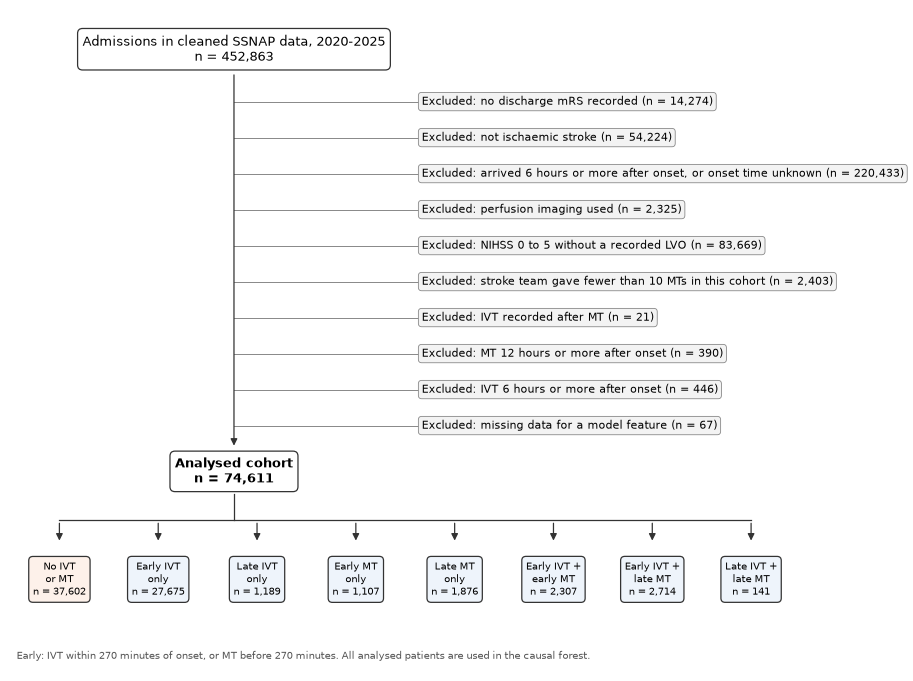

In [6]:
# Patient flow diagram: cohort selection, complete data, and treatment groups
flow_steps = cohort_flow_steps(raw_data)
n_before_complete = flow_steps[-1][0]
flow_extra = [(len(data), "missing data for a model feature", n_before_complete - len(data))]
# Check: only patients with incomplete model features should be lost after the selection steps
assert 0 <= n_before_complete - len(data) < 0.01 * n_before_complete, "Flow counts do not match the cohort in data"

group_counts = data["treatment_group"].value_counts()
flow_groups = [(group, [f"n = {group_counts[group]:,}"]) for group in [CONTROL_GROUP] + GROUP_ORDER]

plot_flow_diagram(
    flow_steps, "Analysed cohort", flow_groups, f"{OUTPUT_DIR}/{prefix}_flow_diagram.png", extra_steps=flow_extra,
    footnote="Early: IVT within 270 minutes of onset, or MT before 270 minutes. All analysed patients are used in the causal forest.")
pd.DataFrame(flow_steps + flow_extra, columns=["n_remaining", "excluded_reason", "n_excluded"]).to_csv(
    f"{OUTPUT_DIR}/{prefix}_flow_counts.csv", index=False)

**Results.** Most exclusions are for arrival 6 hours or more after onset or with unknown onset time (220,433 records), NIHSS 0–5 without a recorded LVO (83,669) and stroke types other than infarction (54,224). The final complete-data step removes 67 patients.

# 3. Descriptive statistics

Baseline characteristics by treatment type (ignoring timing), shown as mean ± SD. The differences between groups are the confounding that the first-stage models have to remove.

In [7]:
has_lysis = data[TIME_THROMBOLYSIS] != NO_TREATMENT
has_ect = data[TIME_THROMBECTOMY] != NO_TREATMENT
treatment_type = np.select([has_lysis & has_ect, has_lysis, has_ect],
                           ["both", "thrombolysis_only", "thrombectomy_only"], default="neither")

descriptive_features = [f for f in W_FEATURES if f not in CATEGORICAL_FEATURES + ["year", "onset_to_scan_time"]]
stats_by_type = data[descriptive_features].groupby(treatment_type).agg(["mean", "std", "count"])

type_order = ["neither", "thrombolysis_only", "thrombectomy_only", "both"]
formatted_descriptive_stats = pd.DataFrame({
    t.replace("_", " "): [f"{stats_by_type.loc[t, (f, 'mean')]:.2f} ± {stats_by_type.loc[t, (f, 'std')]:.2f} "
                          f"(n={int(stats_by_type.loc[t, (f, 'count')])})" for f in descriptive_features]
    for t in type_order
}, index=[f.replace("_", " ") for f in descriptive_features])
formatted_descriptive_stats

,neither,thrombolysis only,thrombectomy only,both
prior disability,1.87 ± 1.60 (n=37602),1.00 ± 1.31 (n=28864),0.67 ± 0.87 (n=2983),0.42 ± 0.73 (n=5162)
stroke severity,12.81 ± 6.75 (n=37602),12.59 ± 6.15 (n=28864),16.74 ± 6.17 (n=2983),16.67 ± 6.05 (n=5162)
age,78.51 ± 12.38 (n=37602),74.19 ± 13.32 (n=28864),72.38 ± 13.30 (n=2983),69.96 ± 13.34 (n=5162)
congestive heart failure,0.09 ± 0.29 (n=37602),0.05 ± 0.23 (n=28864),0.09 ± 0.28 (n=2983),0.04 ± 0.20 (n=5162)
hypertension,0.59 ± 0.49 (n=37602),0.55 ± 0.50 (n=28864),0.53 ± 0.50 (n=2983),0.49 ± 0.50 (n=5162)
diabetes,0.26 ± 0.44 (n=37602),0.21 ± 0.41 (n=28864),0.18 ± 0.38 (n=2983),0.15 ± 0.36 (n=5162)
afib anticoagulant,0.28 ± 0.45 (n=37602),0.03 ± 0.18 (n=28864),0.45 ± 0.50 (n=2983),0.03 ± 0.17 (n=5162)
any afib diagnosis,0.39 ± 0.49 (n=37602),0.21 ± 0.41 (n=28864),0.51 ± 0.50 (n=2983),0.24 ± 0.42 (n=5162)


**Results.** Compared with untreated patients, treated patients are:

* younger (mean age 70.0 to 74.2 vs 78.5 years)
* much less likely to have pre-stroke disability (mean mRS 0.42 to 1.00 vs 1.87)
* among thrombolysed patients, far less likely to be on anticoagulants (3% vs 28%), because anticoagulation is a contraindication to thrombolysis

Thrombectomy patients have more severe strokes (mean NIHSS 16.7 vs 12.8 in untreated patients) and, if given thrombectomy alone, more often have AF (51%) and anticoagulant use (45%). These are large differences, so the adjustment matters.

Mean (SD) onset-to-treatment times by treatment group, for treated patients only.

In [8]:
# Mean (SD) onset-to-treatment times by treatment group (treated patients only)
times = data[TREATMENT_TIMES].replace(NO_TREATMENT, np.nan)
times.groupby(data["treatment_group"]).agg(["mean", "std", "count"]).reindex(GROUP_ORDER).round(1)

onset_to_thrombolysis_time               \
                                                           mean   std  count   
treatment_group                                                                
early_thrombolysis_only                                   164.1  50.3  27675   
late_thrombolysis_only                                    299.7  24.1   1189   
early_thrombectomy_only                                     NaN   NaN      0   
late_thrombectomy_only                                      NaN   NaN      0   
early_both                                                121.8  34.3   2307   
early_thrombolysis_late_thrombectomy                      169.7  48.0   2714   
late_both                                                 304.2  27.4    141   

                                     onset_to_thrombectomy_time               
                                                           mean    std count  
treatment_group                                                               
early_thrombolysis_only                                     NaN    NaN     0  
late_thrombolysis_only                                      NaN    NaN     0  
early_thrombectomy_only                                   207.1   40.7  1107  
late_thrombectomy_only                                    398.2  100.1  1876  
early_both                                                210.4   39.3  2307  
early_thrombolysis_late_thrombectomy                      356.9   76.6  2714  
late_both                                                 439.0   84.3   141

**Results.** Mean onset-to-thrombolysis time is 164 minutes for early thrombolysis only and 122 minutes when thrombolysis is followed by early thrombectomy; late thrombolysis averages 300 to 304 minutes. Mean onset-to-thrombectomy time is 207 to 210 minutes for the early thrombectomy groups and 357 to 439 minutes for the late groups.

# 4. Model

### First-stage (nuisance) models

Two LightGBM models are fitted with 5-fold cross-fitting, so each patient's predictions come from models trained on other patients:

* **outcome model:** probability of a good outcome given `[X, W]`
* **treatment model:** probability of each of the 8 treatment groups given `[X, W]` (the propensity scores)

EconML gives the first-stage models the combined matrix `[X, W]`, so the categorical column indices are calculated for that combined matrix. LightGBM ignores `categorical_feature` when it is passed to the constructor, so small wrapper classes pass it to `.fit()` instead. They are defined at module level so that fitted models can be pickled and cloned.

### Second stage: causal forest

A forest of 2,000 honest trees, each with at least 25 patients per leaf, relates outcome residuals to treatment residuals as a function of X. "Honest" means each tree uses half its sample to choose splits and the other half to estimate effects.

### Cross-fitting groups

`groups` = patient ID, so each patient is in exactly one fold. A sensitivity analysis instead keeps all patients from a stroke team in the same fold.

The cell below also defines the functions that recover cross-fitted predictions, calculate the forest's individual effects (CATE) and calculate the doubly robust ATT and ATE.

In [9]:
class CatLGBMClassifier(LGBMClassifier):
    # LightGBM classifier that passes categorical column indices to .fit()
    def __init__(self, cat_features="auto", **kwargs):
        self.cat_features = cat_features
        super().__init__(**kwargs)

    def get_params(self, deep=True):
        params = super().get_params(deep=deep)
        params["cat_features"] = self.cat_features
        return params

    def fit(self, X, y, **kw):
        kw.setdefault("categorical_feature", self.cat_features)
        return super().fit(X, y, **kw)


def encode_categoricals(frame, cat_cols):
    # Non-negative integer codes for LightGBM's native categorical handling (missing -> "Empty")
    out = frame.copy()
    for col in cat_cols:
        out[col] = (frame[col].astype(str).replace({"nan": "Empty", "": "Empty"})
                    .astype("category").cat.codes.astype(np.int64))
    return out


def build_matrices(df, x_features=X_FEATURES, w_features=W_FEATURES,
                   mrs_target=MRS_TARGET, allow_no_worse_than_prior=True):
    # Returns X, W, outcome y, treatment arm codes, and categorical column indices in [X, W]
    y = df["discharge_disability"] <= mrs_target
    if allow_no_worse_than_prior:
        y = y | (df["discharge_disability"] <= df["prior_disability"])
    encoded = encode_categoricals(df, CATEGORICAL_FEATURES)
    X, W = encoded[list(x_features)], encoded[list(w_features)]
    # EconML fits the first-stage models on hstack([X, W]), so indices refer to that matrix
    cat_idx = ([X.columns.get_loc(c) for c in CATEGORICAL_FEATURES if c in X.columns]
               + [X.shape[1] + W.columns.get_loc(c) for c in CATEGORICAL_FEATURES if c in W.columns])
    arm = df["treatment_group"].map(ARM_CODES).to_numpy()
    return X, W, y.astype(int).to_numpy(), arm, cat_idx


def fit_causal_forest(df, seed=SEED, nuisance_params=NUISANCE_PARAMS, n_trees=N_TREES,
                      min_samples_leaf=MIN_SAMPLES_LEAF, groups="patient", cat_idx_override=None,
                      **matrix_kwargs):
    # Fit CausalForestDML; returns (estimator, X, W, y, arm, seconds)
    X, W, y, arm, cat_idx = build_matrices(df, **matrix_kwargs)
    if cat_idx_override is not None:
        cat_idx = cat_idx_override
    params = dict(nuisance_params, random_state=seed)
    est = CausalForestDML(
        model_y=CatLGBMClassifier(cat_features=cat_idx, **params),
        model_t=CatLGBMClassifier(cat_features=cat_idx, **params),
        discrete_treatment=True, discrete_outcome=True,
        n_estimators=n_trees, min_samples_leaf=min_samples_leaf, max_depth=None,
        honest=True, cv=CV_FOLDS, random_state=seed, n_jobs=-1, verbose=False,
    )
    fold_groups = (df["patient_id"] if groups == "patient" else df["stroke_team"].astype(str)).to_numpy()
    start = time.time()
    est.fit(y, arm, X=X, W=W, groups=fold_groups, cache_values=True)
    return est, X, W, y, arm, time.time() - start


def cate_matrix(est, X):
    # Forest CATE for every patient and every treatment vs neither: shape (n, number of treatments),
    # columns in lexicographic order of arm codes (= GROUP_ORDER)
    return np.asarray(est.const_marginal_effect(np.asarray(X))).reshape(len(X), -1)


def nuisance_predictions(est, y, arm):
    # Cross-fitted first-stage predictions recovered from cached residuals (prediction = observed - residual):
    #   m  = P(good outcome | X, W);  p[:, j] = P(treatment j | X, W);  p0 = P(neither | X, W)
    y_res, t_res = est.residuals_[0], est.residuals_[1]
    treated_levels = sorted(a for a in np.unique(arm) if a != BASELINE_ARM)
    onehot = np.column_stack([(arm == a) for a in treated_levels]).astype(float)
    p = onehot - np.asarray(t_res).reshape(len(arm), -1)
    return y - np.ravel(y_res), p, 1 - p.sum(axis=1), treated_levels


def dr_effects(est, X, y, arm, analysis="Primary", category="Primary", clip=PROPENSITY_CLIP):
    # Doubly robust (AIPW) ATT and ATE for each treatment vs neither, with influence-function 95% CIs.
    # The DML model implies outcome predictions for each treatment:
    #   mu0 = m - sum_l theta_l * p_l  (neither);   mu_j = mu0 + theta_j
    m, p, p0, treated_levels = nuisance_predictions(est, y, arm)
    theta = cate_matrix(est, X)
    p_c, p0_c = np.clip(p, clip, 1), np.clip(p0, clip, 1)
    mu0 = m - (theta * p).sum(axis=1)
    is0 = (arm == BASELINE_ARM).astype(float)
    n = len(y)
    rows = []
    for j, level in enumerate(treated_levels):
        isj = (arm == level).astype(float)
        resid0 = y - mu0
        # ATT: treated patients' outcome minus a DR estimate of their outcome without treatment;
        # untreated patients are reweighted by the odds P(j) / P(neither)
        odds = p_c[:, j] / p0_c
        att = (isj * resid0 - is0 * odds * resid0).sum() / isj.sum()
        psi_att = (isj * (resid0 - att) - is0 * odds * resid0) / isj.mean()
        att_se = psi_att.std(ddof=1) / np.sqrt(n)
        # ATE: standard AIPW score
        psi_ate = theta[:, j] + isj * (y - mu0 - theta[:, j]) / p_c[:, j] - is0 * resid0 / p0_c
        ate, ate_se = psi_ate.mean(), psi_ate.std(ddof=1) / np.sqrt(n)
        pct_clipped = 100 * (p[:, j] < clip).mean()
        if pct_clipped > ATE_MAX_CLIPPED_PCT:  # positivity fails for the whole cohort: ATE not estimable
            ate = ate_se = np.nan
        treated = isj.astype(bool)
        rows.append({
            "category": category, "analysis": analysis, "treatment_group": level.split("_", 1)[1],
            "n": int(isj.sum()),
            "att": att, "att_ci_lower": att - 1.96 * att_se, "att_ci_upper": att + 1.96 * att_se,
            "ate": ate, "ate_ci_lower": ate - 1.96 * ate_se, "ate_ci_upper": ate + 1.96 * ate_se,
            "pct_cohort_p_below_clip": pct_clipped,
            "mean_cate": theta[treated, j].mean(), "cate_sd_between_patients": theta[treated, j].std(),
        })
    return pd.DataFrame(rows)

### Fit the primary model

This is the slowest step. The fitting time is printed so you can judge how long the sensitivity analyses will take.

In [10]:
est, X, W, y, arm, fit_seconds = fit_causal_forest(data)
print(f"Fitted in {fit_seconds / 60:.1f} minutes")

Fitted in 3.4 minutes


**Results.** The primary model fitted in 3.4 minutes.

# 5. Model diagnostics

### First-stage model performance

The doubly robust estimates rely on the first-stage models predicting outcome and treatment reasonably well. Cross-fitted predictions are recovered from the cached residuals (prediction = observed − residual). Discrimination is measured with the ROC AUC (0.5 = no better than chance, 1 = perfect). For the treatment model, one AUC is given per treatment group (that group vs all others).

In [11]:
y_res, t_res = est.residuals_[0], est.residuals_[1]
outcome_pred = y - np.ravel(y_res)

arm_levels = sorted(np.unique(arm))
treated_levels = [a for a in arm_levels if a != BASELINE_ARM]
onehot = np.column_stack([(arm == a).astype(float) for a in treated_levels])
propensity = pd.DataFrame(onehot - np.asarray(t_res).reshape(len(arm), -1),
                          columns=[a.split("_", 1)[1] for a in treated_levels])
propensity.insert(0, CONTROL_GROUP, 1 - propensity.sum(axis=1))

performance = [{"model": "Outcome (good outcome)", "auc": roc_auc_score(y, outcome_pred)}]
for group in [CONTROL_GROUP] + GROUP_ORDER:
    performance.append({"model": f"Treatment: {group}",
                        "auc": roc_auc_score(data["treatment_group"] == group, propensity[group])})
pd.DataFrame(performance).round(3)

,model,auc
0,Outcome (good outcome),0.753
1,Treatment: neither,0.772
2,Treatment: early_thrombolysis_only,0.728
3,Treatment: late_thrombolysis_only,0.679
4,Treatment: early_thrombectomy_only,0.906
5,Treatment: late_thrombectomy_only,0.824
6,Treatment: early_both,0.886
7,Treatment: early_thrombolysis_late_thrombectomy,0.831
8,Treatment: late_both,0.771


**Results.**

* **Outcome model:** AUC 0.753.
* **Treatment model:** AUC 0.679 to 0.906. It is highest for early thrombectomy only (0.906) and early both (0.886), and lowest for late thrombolysis only (0.679) and early thrombolysis only (0.728).

**Discussion.** The first-stage models capture most of the measured differences between patients. Thrombectomy strategies are highly predictable from baseline characteristics and stroke team, which shows how strong the confounding is. The thrombolysis-only strategies are less predictable, because the model is not given onset-to-scan time and so has little information on whether treatment could be given early.

### Overlap (positivity)

To estimate the effect of a treatment in the patients who received it, there must be untreated patients with similar characteristics. The key quantity is each treated patient's estimated probability of receiving **neither** treatment, P(neither | X, W). If it is close to zero, there are effectively no comparable untreated patients. The estimate then depends on extrapolation and on large inverse-probability weights in the doubly robust correction. The table gives the median P(neither) and the percentage of patients below 0.05 and 0.01 in each group; the histogram shows the distributions.

,treatment_group,n,median P(neither),% with P(neither) < 0.05,% with P(neither) < 0.01
0,neither,37602,0.633,0.005,0.0
1,early_thrombolysis_only,27675,0.370,0.025,0.0
2,late_thrombolysis_only,1189,0.363,0.000,0.0
3,early_thrombectomy_only,1107,0.335,0.452,0.0
4,late_thrombectomy_only,1876,0.361,0.107,0.0
5,early_both,2307,0.217,0.520,0.0
6,early_thrombolysis_late_thrombectomy,2714,0.252,0.074,0.0
7,late_both,141,0.234,0.000,0.0


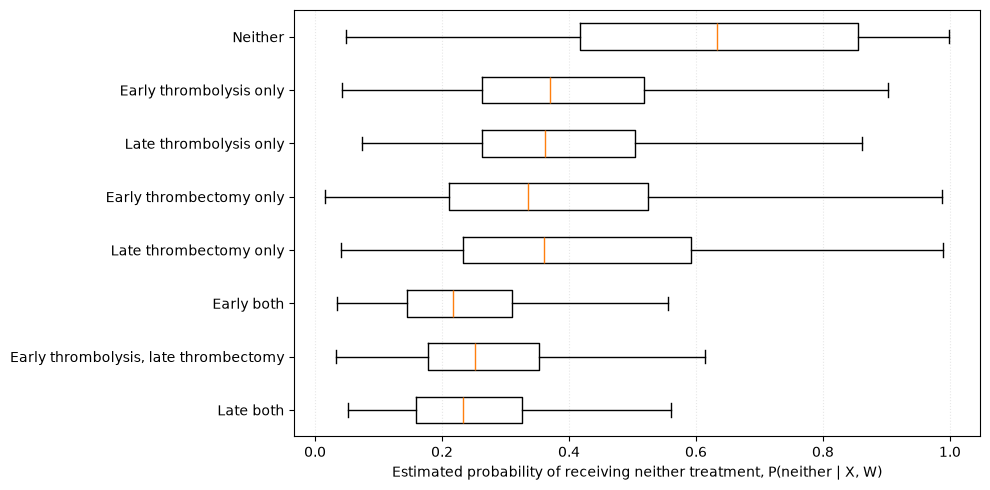

In [12]:
p_neither = propensity[CONTROL_GROUP].to_numpy()
overlap = pd.DataFrame([
    {"treatment_group": g,
     "n": int(mask.sum()),
     "median P(neither)": np.median(p_neither[mask]),
     "% with P(neither) < 0.05": 100 * (p_neither[mask] < 0.05).mean(),
     "% with P(neither) < 0.01": 100 * (p_neither[mask] < 0.01).mean()}
    for g in [CONTROL_GROUP] + GROUP_ORDER
    for mask in [(data["treatment_group"] == g).to_numpy()]
]).round(3)
display(overlap)

fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot([p_neither[(data["treatment_group"] == g).to_numpy()] for g in [CONTROL_GROUP] + GROUP_ORDER],
           vert=False, showfliers=False)
ax.set_yticklabels(["Neither"] + [GROUP_LABELS[g].replace("\n", " ") for g in GROUP_ORDER])
ax.invert_yaxis()
ax.set_xlabel("Estimated probability of receiving neither treatment, P(neither | X, W)")
ax.grid(axis="x", alpha=0.3, linestyle=":")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/{prefix}_overlap.png", dpi=300)
plt.show()

**Results.**

* **Median P(neither):** among treated patients, it ranges from 0.22 (early both) to 0.37 (early thrombolysis only); among untreated patients it is 0.63.
* **Patients with very low P(neither):** at most 0.52% of any treated group (early both) have P(neither) < 0.05, and no patient is below 0.01.

**Discussion.** Overlap is good for estimating the effect in the treated: almost every treated patient has comparable untreated patients, so the ATT does not depend on extreme weights. A sensitivity analysis excludes the few patients with P(neither) < 0.05.

# 6. Treatment effects

For each strategy compared with neither treatment, three estimates are shown:

* **ATT** (main result): the AIPW estimate of the average effect in patients who received the strategy. Each treated patient's outcome is compared with a doubly robust estimate of their outcome without treatment. This combines the first-stage predictions, the forest, and untreated patients reweighted by the odds P(strategy | X, W) / P(neither | X, W). It is consistent if either the outcome or the treatment model is correct. The 95% CI comes from the influence function.
* **ATE:** the AIPW estimate of the average effect if everyone in the cohort received the strategy. This needs every type of patient to have some chance of receiving the strategy (positivity). The ATE is shown as "not estimable" when more than 20% of the cohort has a predicted probability of the strategy below 0.01.
* **Mean CATE in treated:** the simple average of the forest's individual estimates in treated patients. No CI is given, because individual estimates share the same trees and are strongly correlated.

Propensities are clipped at 0.01. Effects are differences in the probability of a good outcome, shown in percentage points. The effects are saved to CSV.

In [13]:
effects = dr_effects(est, X, y, arm)
effects.to_csv(f"{OUTPUT_DIR}/{prefix}_effects.csv", index=False)

# Per-patient CATE for each patient's own strategy (vs neither)
theta = cate_matrix(est, X)
cate_df = data[X_FEATURES + ["treatment_group"]].copy()
cate_df["good_outcome"] = y
cate_df["cate"] = np.nan
for j, group in enumerate(GROUP_ORDER):
    mask = (data["treatment_group"] == group).to_numpy()
    cate_df.loc[mask, "cate"] = theta[mask, j]
cate_df.to_csv(f"{OUTPUT_DIR}/{prefix}_causal_forest_cate_estimates.csv", index=True)


def fmt_pp(point, lower, upper):
    if pd.isna(point):
        return "not estimable (positivity)"
    return f"{100 * point:.1f} ({100 * lower:.1f}, {100 * upper:.1f})"


effects_table = pd.DataFrame({
    "Treatment group": effects["treatment_group"].str.replace("_", " "),
    "n": effects["n"],
    "ATT, % points (95% CI)": [fmt_pp(*r) for r in effects[["att", "att_ci_lower", "att_ci_upper"]].to_numpy()],
    "ATE, % points (95% CI)": [fmt_pp(*r) for r in effects[["ate", "ate_ci_lower", "ate_ci_upper"]].to_numpy()],
    "% of cohort with P(strategy) < 0.01": effects["pct_cohort_p_below_clip"].round(1),
    "Mean CATE in treated, % points": (100 * effects["mean_cate"]).round(1),
    "SD of CATE between patients": (100 * effects["cate_sd_between_patients"]).round(1),
})
effects_table.to_csv(f"{OUTPUT_DIR}/{prefix}_effects_table.csv", index=False)
effects_table

,Treatment group,n,"ATT, % points (95% CI)","ATE, % points (95% CI)",% of cohort with P(strategy) < 0.01,"Mean CATE in treated, % points",SD of CATE between patients
0,early thrombolysis only,27675,"13.1 (12.2, 13.9)","11.5 (10.4, 12.6)",1.0,12.6,5.9
1,late thrombolysis only,1189,"8.5 (5.7, 11.2)",not estimable (positivity),51.9,7.8,16.3
2,early thrombectomy only,1107,"17.6 (14.1, 21.1)",not estimable (positivity),81.2,15.9,14.9
3,late thrombectomy only,1876,"8.5 (6.3, 10.8)",not estimable (positivity),57.1,7.2,11.8
4,early both,2307,"23.7 (21.2, 26.2)",not estimable (positivity),63.5,21.5,12.0
5,early thrombolysis late thrombectomy,2714,"12.0 (9.8, 14.1)",not estimable (positivity),49.4,10.5,10.2
6,late both,141,"14.9 (5.7, 24.1)",not estimable (positivity),98.4,13.5,31.8


**Results.**

* **ATT (main result):** every strategy improves the probability of a good outcome in the patients who received it, and all CIs exclude zero:
  * early thrombolysis only: +13.1 points (12.2 to 13.9)
  * late thrombolysis only: +8.5 (5.7 to 11.2)
  * early thrombectomy only: +17.6 (14.1 to 21.1)
  * late thrombectomy only: +8.5 (6.3 to 10.8)
  * early both: +23.7 (21.2 to 26.2)
  * early thrombolysis, late thrombectomy: +12.0 (9.8 to 14.1)
  * late both: +14.9 (5.7 to 24.1; only 141 patients)
* **Mean CATE in treated:** 0.5 to 2.2 points below the ATT for every strategy (for example early both 21.5, early thrombolysis only 12.6), so the forest and the doubly robust correction broadly agree.
* **ATE:** can only be estimated for early thrombolysis only (+11.5, 10.4 to 12.6), slightly lower than its ATT. For the other strategies, 49% to 98% of the cohort has less than a 1% predicted chance of receiving them, so a whole-cohort effect would be pure extrapolation.
* **SD of CATE between patients** (6 to 32 points) mixes real differences between patients with estimation noise, so it should not be read as the true spread of effects.

**Discussion.** Earlier treatment is associated with larger effects: thrombolysis only +13.1 early vs +8.5 late, thrombectomy only +17.6 early vs +8.5 late, and after early thrombolysis +23.7 with early vs +12.0 with late thrombectomy. The ATE for early thrombolysis being slightly below its ATT is consistent with thrombolysis being given to patients who benefit more.

### Comparison with EconML's built-in doubly robust estimates

EconML also provides doubly robust ATT estimates (`att__inference`). This cell shows them alongside the AIPW ATT used here, together with the smallest predicted probability of each patient's *own* treatment among the treated. EconML divides by these probabilities without clipping.

In [14]:
builtin = []
arm_levels = sorted(np.unique(arm))
for k, level in enumerate(arm_levels):
    if level == BASELINE_ARM:
        continue
    group = level.split("_", 1)[1]
    mask = (data["treatment_group"] == group).to_numpy()
    builtin.append({
        "treatment_group": group,
        "EconML att__inference, % points": round(100 * float(np.ravel(est.att__inference(T=k).point_estimate)[k - 1]), 1),
        "AIPW ATT (clipped), % points": round(100 * float(effects.set_index("treatment_group").loc[group, "att"]), 1),
        "smallest P(own treatment) in treated": propensity[group][mask].min(),
    })
pd.DataFrame(builtin)

,treatment_group,"EconML att__inference, % points","AIPW ATT (clipped), % points",smallest P(own treatment) in treated
0,early_thrombolysis_only,10.3,13.1,0.001398
1,late_thrombolysis_only,83.4,8.5,0.000170
2,early_thrombectomy_only,42.2,17.6,0.000086
3,late_thrombectomy_only,33.5,8.5,0.000077
4,early_both,6.3,23.7,0.000170
5,early_thrombolysis_late_thrombectomy,14.1,12.0,0.000295
6,late_both,-1138.6,14.9,0.000002


**Results.**

* **EconML's built-in values are implausible for most strategies:** +83.4 points (late thrombolysis only), +42.2 (early thrombectomy only), +33.5 (late thrombectomy only) and −1,138.6 (late both).
* **Why:** some treated patients have a predicted probability of their own treatment as low as 0.000002 (late both), or about 0.0001 to 0.0014 (other strategies). Dividing by these gives enormous weights.

**Discussion.** The AIPW ATT used here clips probabilities at 0.01 and reweights only untreated patients. It gives stable estimates that agree with the forest's own averages, so it is used for all results.

### Plot of treatment effects

ATT (and ATE where estimable) with 95% CI for each strategy, in percentage points.

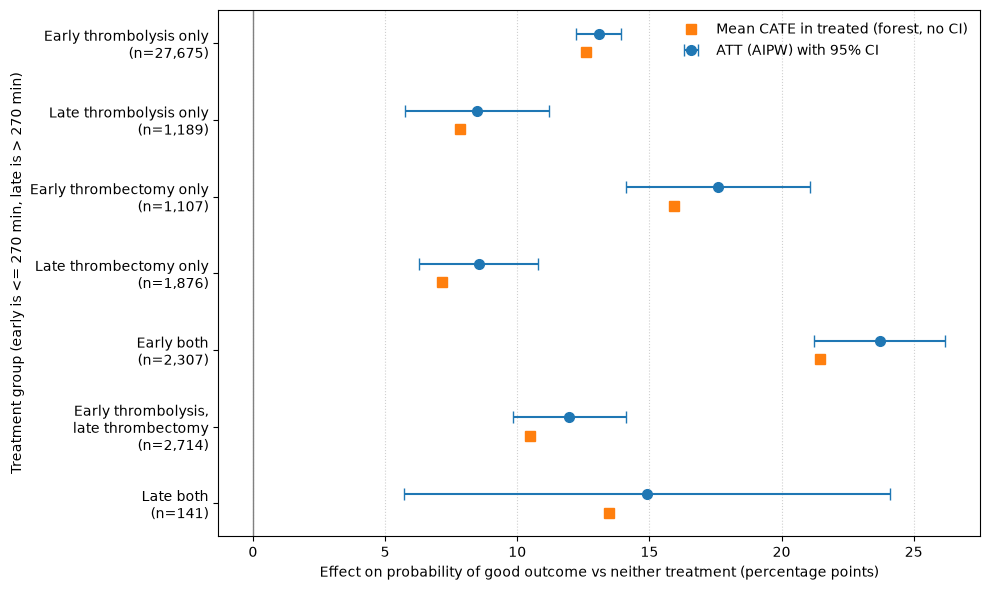

In [15]:
fig, ax = plt.subplots(figsize=(10, 6))
ypos = np.arange(len(effects))[::-1]
point = 100 * effects["att"]
ax.errorbar(point, ypos + 0.12, xerr=[point - 100 * effects["att_ci_lower"], 100 * effects["att_ci_upper"] - point],
            fmt="o", color="#1f77b4", capsize=4, markersize=7, label="ATT (AIPW) with 95% CI")
ax.plot(100 * effects["mean_cate"], ypos - 0.12, "s", color="#ff7f0e", markersize=7,
        label="Mean CATE in treated (forest, no CI)")
ax.set_yticks(ypos)
ax.set_yticklabels([f"{GROUP_LABELS[g]}\n(n={n:,})" for g, n in zip(effects["treatment_group"], effects["n"])])
ax.axvline(0, color="0.5", lw=1)
ax.set_xlabel("Effect on probability of good outcome vs neither treatment (percentage points)")
ax.set_ylabel(f"Treatment group (early is <= {CUTOFF} min, late is > {CUTOFF} min)")
ax.grid(axis="x", linestyle=":", alpha=0.6)
ax.legend(loc="upper right", frameon=False)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/{prefix}_cate.png", dpi=300)
plt.show()

**Results.** The plot shows every ATT above zero, the largest point estimates for early both and early thrombectomy only, and the much wider CI for late both, reflecting its small size.

# 7. Heterogeneity of effects

The forest estimates an effect for each patient (CATE). Here those estimates are averaged within subgroups of the treated patients in each strategy, by NIHSS, age and pre-stroke mRS. Subgroups with fewer than 50 patients are not shown.

Individual CATEs are noisy, and these subgroup averages have no CIs, so they show *patterns* rather than precise subgroup effects.

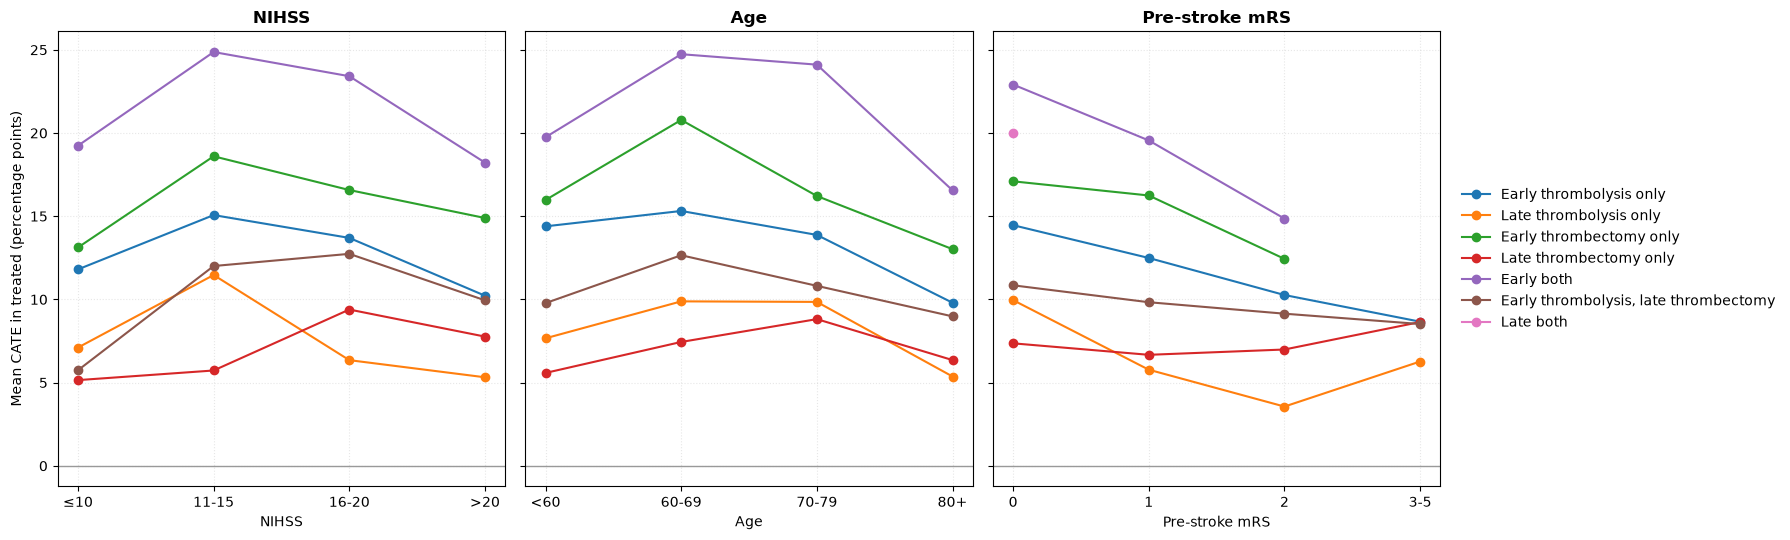

treatment_group       early_thrombolysis_only  late_thrombolysis_only  \
characteristic band                                                     
Age            60-69                     15.3                     9.9   
               70-79                     13.9                     9.8   
               80+                        9.8                     5.4   
               <60                       14.4                     7.7   
NIHSS          11-15                     15.1                    11.5   
               16-20                     13.7                     6.3   
               >20                       10.2                     5.3   
               ≤10                       11.8                     7.1   
Pre-stroke mRS 0                         14.5                    10.0   
               1                         12.5                     5.8   
               2                         10.3                     3.6   
               3-5                        8.7                     6.3   

treatment_group       early_thrombectomy_only  late_thrombectomy_only  \
characteristic band                                                     
Age            60-69                     20.8                     7.4   
               70-79                     16.2                     8.8   
               80+                       13.0                     6.4   
               <60                       16.0                     5.6   
NIHSS          11-15                     18.6                     5.7   
               16-20                     16.6                     9.4   
               >20                       14.9                     7.8   
               ≤10                       13.1                     5.1   
Pre-stroke mRS 0                         17.1                     7.4   
               1                         16.2                     6.7   
               2                         12.4                     7.0   
               3-5                       12.4                     8.6   

treatment_group       early_both  early_thrombolysis_late_thrombectomy  \
characteristic band                                                      
Age            60-69        24.7                                  12.7   
               70-79        24.1                                  10.8   
               80+          16.6                                   9.0   
               <60          19.7                                   9.8   
NIHSS          11-15        24.9                                  12.0   
               16-20        23.4                                  12.7   
               >20          18.2                                   9.9   
               ≤10          19.2                                   5.7   
Pre-stroke mRS 0            22.9                                  10.8   
               1            19.6                                   9.8   
               2            14.9                                   9.1   
               3-5          16.1                                   8.5   

treatment_group       late_both  
characteristic band              
Age            60-69       19.1  
               70-79       10.2  
               80+         18.0  
               <60          7.7  
NIHSS          11-15       16.8  
               16-20       22.8  
               >20         12.8  
               ≤10          2.8  
Pre-stroke mRS 0           20.0  
               1            4.0  
               2            0.0  
               3-5        -29.8

In [16]:
bands = {
    "NIHSS": pd.cut(data["stroke_severity"], [0, 10, 15, 20, 42], labels=["≤10", "11-15", "16-20", ">20"]),
    "Age": pd.cut(data["age"], [0, 60, 70, 80, 120], right=False, labels=["<60", "60-69", "70-79", "80+"]),
    "Pre-stroke mRS": pd.cut(data["prior_disability"], [-1, 0, 1, 2, 5], labels=["0", "1", "2", "3-5"]),
}
heterogeneity = []
for band_name, band in bands.items():
    grouped = cate_df.assign(band=band).groupby(["treatment_group", "band"], observed=True)["cate"]
    summary = grouped.agg(["mean", "count"]).reset_index()
    summary.insert(0, "characteristic", band_name)
    heterogeneity.append(summary)
heterogeneity = pd.concat(heterogeneity, ignore_index=True)
heterogeneity = heterogeneity[heterogeneity["treatment_group"] != CONTROL_GROUP]
heterogeneity.to_csv(f"{OUTPUT_DIR}/{prefix}_heterogeneity.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharey=True)
for ax, band_name in zip(axes, bands):
    for group in GROUP_ORDER:
        h = heterogeneity[(heterogeneity["characteristic"] == band_name)
                          & (heterogeneity["treatment_group"] == group) & (heterogeneity["count"] >= 50)]
        ax.plot(h["band"].astype(str), 100 * h["mean"], marker="o", label=GROUP_LABELS[group].replace("\n", " "))
    ax.set_title(band_name, fontweight="bold")
    ax.set_xlabel(band_name)
    ax.axhline(0, color="0.6", lw=1)
    ax.grid(alpha=0.3, linestyle=":")
axes[0].set_ylabel("Mean CATE in treated (percentage points)")
axes[-1].legend(loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/{prefix}_heterogeneity.png", dpi=300)
plt.show()

(heterogeneity.assign(mean=lambda d: (100 * d["mean"]).round(1))
 .pivot_table(index=["characteristic", "band"], columns="treatment_group", values="mean", observed=True)
 .reindex(columns=GROUP_ORDER))

**Results** (patterns only; subgroup estimates are noisy):

* **Age:** the benefit is smaller in patients aged 80+ for most strategies:
  * early thrombolysis only: +9.8 at 80+ vs +13.9 to +15.3 under 80
  * late thrombolysis only: +5.4 at 80+ vs +7.7 to +9.9 under 80
  * early thrombectomy only: +13.0 at 80+ vs +16.0 to +20.8 under 80
  * early both: +16.6 at 80+ vs +24.1 to +24.7 at ages 60–79 (+19.7 under 60)
* **Pre-stroke disability:** the benefit generally falls as pre-stroke mRS rises:
  * early thrombolysis only: +14.5 at mRS 0 to +8.7 at mRS 3–5
  * early thrombectomy only: +17.1 at mRS 0 to +12.4 at mRS 2 or more
  * early both: +22.9 at mRS 0 to +14.9 to +19.6 at mRS 1 or more
* **Stroke severity:**
  * Thrombolysis only and early both: the benefit is largest at NIHSS 11–15 (early thrombolysis only +15.1, late thrombolysis only +11.5, early both +24.9) and smaller at NIHSS > 20 (early thrombolysis only +10.2, early both +18.2) and ≤ 10 (+11.8, +19.2).
  * Early thrombectomy only: the benefit is lowest at NIHSS ≤ 10 (+13.1) and highest at 11–15 (+18.6); early thrombolysis with late thrombectomy is also lowest at NIHSS ≤ 10 (+5.7 vs +9.9 to +12.7).
* **Late both:** estimates jump around between subgroups (for example −29.8 at pre-stroke mRS 3–5), reflecting very small numbers rather than real effects.

# 8. Relative effects, first-stage performance and a test of heterogeneity

* **Relative effects:** risk ratio in the treated, the observed proportion with a good outcome divided by the doubly robust estimate of that proportion without treatment, with influence-function 95% CIs (TARGET item 13).
* **First-stage performance:** bootstrap 95% CIs for the ROC AUCs, and calibration of the first-stage outcome model by decile, with calibration intercept and slope (TRIPOD items 10d and 16).
* **Best linear predictor (BLP) test:** for each strategy, within patients with adequate overlap, the doubly robust effect is regressed on the forest's (out-of-bag) CATE. A slope above zero means the forest detects real differences in benefit between patients; a slope near 1 means its estimates are well calibrated.

Results are also printed as LaTeX rows for the paper.

,treatment_group,n,treated_proportion,untreated_proportion_dr,att,rr,rr_ci_lower,rr_ci_upper
0,early_thrombolysis_only,27675,0.490,0.359,0.131,1.364,1.335,1.394
1,late_thrombolysis_only,1189,0.472,0.387,0.085,1.219,1.148,1.294
2,early_thrombectomy_only,1107,0.388,0.212,0.176,1.830,1.612,2.077
3,late_thrombectomy_only,1876,0.336,0.250,0.085,1.341,1.245,1.444
4,early_both,2307,0.463,0.226,0.237,2.048,1.883,2.228
5,early_thrombolysis_late_thrombectomy,2714,0.372,0.252,0.120,1.474,1.374,1.581
6,late_both,141,0.440,0.291,0.149,1.513,1.170,1.956


,auc,auc_ci_lower,auc_ci_upper
Outcome (good outcome),0.753,0.748,0.756
Treatment: neither,0.772,0.769,0.774
Treatment: early_thrombolysis_only,0.728,0.724,0.731
Treatment: late_thrombolysis_only,0.679,0.671,0.689
Treatment: early_thrombectomy_only,0.906,0.900,0.914
Treatment: late_thrombectomy_only,0.824,0.817,0.831
Treatment: early_both,0.886,0.879,0.891
Treatment: early_thrombolysis_late_thrombectomy,0.831,0.823,0.837
Treatment: late_both,0.771,0.736,0.801


,estimate,ci_lower,ci_upper
Calibration intercept,0.000,-0.013,0.016
Calibration slope,0.942,0.919,0.955


,n,predicted,observed
decile,,,
1,7462,0.084,0.091
2,7461,0.160,0.166
3,7461,0.229,0.245
4,7461,0.303,0.313
5,7461,0.377,0.385
6,7461,0.452,0.450
7,7461,0.527,0.517
8,7461,0.603,0.598
9,7461,0.686,0.670


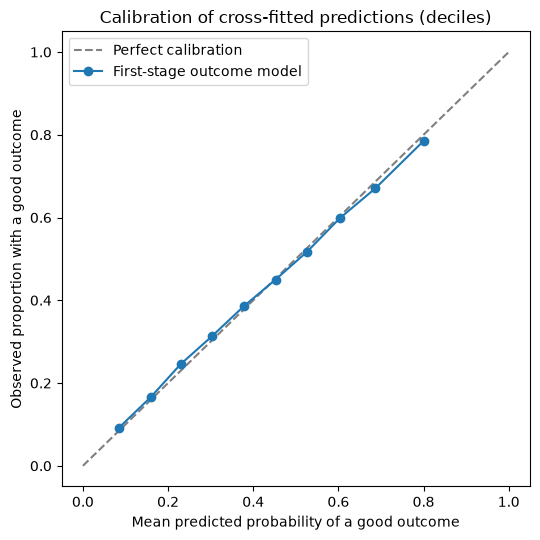

CATE used for the BLP test: out-of-bag


,treatment_group,n_in_overlap,n_treated_in_overlap,mean_effect,mean_effect_se,blp_slope,blp_slope_ci_lower,blp_slope_ci_upper,p_value_slope_gt_0
0,early_thrombolysis_only,59542,27456,0.115,0.004,0.476,0.324,0.629,0.000
1,late_thrombolysis_only,7332,621,0.087,0.019,0.170,-0.119,0.459,0.124
2,early_thrombectomy_only,4049,816,0.212,0.024,0.397,-0.017,0.811,0.030
3,late_thrombectomy_only,8925,1435,0.063,0.016,0.093,-0.245,0.432,0.295
4,early_both,7668,2016,0.211,0.016,0.348,0.102,0.595,0.003
5,early_thrombolysis_late_thrombectomy,10627,2343,0.113,0.014,0.095,-0.245,0.434,0.293
6,late_both,239,15,0.123,0.111,-0.469,-1.378,0.440,0.844


% ---- Relative effects (RR, 95% CI) ----
early_thrombolysis_only & 27,675 & 49.0 & 35.9 & 1.36 (1.34--1.39) \\
late_thrombolysis_only & 1,189 & 47.2 & 38.7 & 1.22 (1.15--1.29) \\
early_thrombectomy_only & 1,107 & 38.8 & 21.2 & 1.83 (1.61--2.08) \\
late_thrombectomy_only & 1,876 & 33.6 & 25.0 & 1.34 (1.25--1.44) \\
early_both & 2,307 & 46.3 & 22.6 & 2.05 (1.88--2.23) \\
early_thrombolysis_late_thrombectomy & 2,714 & 37.2 & 25.2 & 1.47 (1.37--1.58) \\
late_both & 141 & 44.0 & 29.1 & 1.51 (1.17--1.96) \\
% ---- First-stage AUC (95% CI, bootstrap) ----
% Outcome (good outcome): 0.753 (0.748--0.756)
% Treatment: neither: 0.772 (0.769--0.774)
% Treatment: early_thrombolysis_only: 0.728 (0.724--0.731)
% Treatment: late_thrombolysis_only: 0.679 (0.671--0.689)
% Treatment: early_thrombectomy_only: 0.906 (0.900--0.914)
% Treatment: late_thrombectomy_only: 0.824 (0.817--0.831)
% Treatment: early_both: 0.886 (0.879--0.891)
% Treatment: early_thrombolysis_late_thrombectomy: 0.831 (0.823--0.837)
% 

In [17]:
# Additional reporting for the causal forest (TARGET item 13; TRIPOD items 10d and 16):
# 1. Relative effects: risk ratio (RR) in the treated, observed proportion with a good outcome divided
#    by the doubly robust estimate of that proportion without treatment, with 95% CIs from the
#    influence function (delta method on the log scale), consistent with the ATT confidence intervals.
# 2. 95% CIs for first-stage ROC AUCs from N_BOOT bootstrap samples of the cross-fitted predictions.
# 3. Calibration of the first-stage outcome model: by decile, and calibration intercept and slope.
# 4. Heterogeneity: best linear predictor (BLP) test for each strategy against neither treatment.
#    Among patients given the strategy or neither, with conditional probability of the strategy
#    between 0.05 and 0.95, the doubly robust pseudo-outcome is regressed on the centred CATE.
#    A slope above zero shows that the forest detects real differences in benefit between patients;
#    a slope near 1 shows that those differences are well calibrated.

import math

import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

N_BOOT = 30
OVERLAP_BOUNDS = (0.05, 0.95)

m_hat, p_hat, p0_hat, treated_levels_cf = nuisance_predictions(est, y, arm)
theta_all = cate_matrix(est, X)
p_clip, p0_clip = np.clip(p_hat, PROPENSITY_CLIP, 1), np.clip(p0_hat, PROPENSITY_CLIP, 1)
mu0_hat = m_hat - (theta_all * p_hat).sum(axis=1)
is_neither = (arm == BASELINE_ARM).astype(float)
n_patients = len(y)

# 1. Risk ratios with influence-function confidence intervals
rr_rows = []
for j, level in enumerate(treated_levels_cf):
    is_j = (arm == level).astype(float)
    resid0 = y - mu0_hat
    odds = p_clip[:, j] / p0_clip
    p1 = (is_j * y).sum() / is_j.sum()  # observed proportion with a good outcome in the treated
    att_j = (is_j * resid0 - is_neither * odds * resid0).sum() / is_j.sum()
    q0 = p1 - att_j  # doubly robust estimate of that proportion without treatment
    psi_p1 = is_j * (y - p1) / is_j.mean()
    psi_att = (is_j * (resid0 - att_j) - is_neither * odds * resid0) / is_j.mean()
    psi_q0 = psi_p1 - psi_att
    psi_log_rr = psi_p1 / p1 - psi_q0 / q0
    se_log_rr = psi_log_rr.std(ddof=1) / np.sqrt(n_patients)
    rr_rows.append({
        "treatment_group": level.split("_", 1)[1], "n": int(is_j.sum()),
        "treated_proportion": p1, "untreated_proportion_dr": q0, "att": att_j,
        "rr": p1 / q0,
        "rr_ci_lower": np.exp(np.log(p1 / q0) - 1.96 * se_log_rr),
        "rr_ci_upper": np.exp(np.log(p1 / q0) + 1.96 * se_log_rr),
    })
relative_effects = pd.DataFrame(rr_rows)
relative_effects.to_csv(f"{OUTPUT_DIR}/{prefix}_relative_effects.csv", index=False)
display(relative_effects.round(3))


def calibration_intercept_slope(y_true, prob):
    """Calibration intercept (slope fixed at 1) and calibration slope on the logit scale."""
    prob = np.clip(prob, 1e-6, 1 - 1e-6)
    logit = np.log(prob / (1 - prob))
    slope = LogisticRegression(C=1e12, max_iter=1000).fit(logit.reshape(-1, 1), y_true).coef_[0, 0]
    a = 0.0
    for _ in range(50):
        p = 1 / (1 + np.exp(-(a + logit)))
        a += (y_true - p).sum() / (p * (1 - p)).sum()
    return a, slope


# 2 and 3. Bootstrap CIs for AUCs and calibration
boot_rng = np.random.default_rng(SEED)
model_predictions = {"Outcome (good outcome)": (y, m_hat)}
for group in [CONTROL_GROUP] + GROUP_ORDER:
    model_predictions[f"Treatment: {group}"] = (
        (data["treatment_group"] == group).to_numpy().astype(int), propensity[group].to_numpy())

point_auc = {name: roc_auc_score(t, p) for name, (t, p) in model_predictions.items()}
point_cal = calibration_intercept_slope(y, m_hat)
boot_auc, boot_cal = [], []
for _ in range(N_BOOT):
    i = boot_rng.integers(0, n_patients, n_patients)
    boot_auc.append({name: roc_auc_score(t[i], p[i]) for name, (t, p) in model_predictions.items()})
    boot_cal.append(calibration_intercept_slope(y[i], m_hat[i]))
boot_auc, boot_cal = pd.DataFrame(boot_auc), np.array(boot_cal)

first_stage_performance = pd.DataFrame({
    "auc": pd.Series(point_auc),
    "auc_ci_lower": boot_auc.quantile(0.025),
    "auc_ci_upper": boot_auc.quantile(0.975),
})
first_stage_performance.to_csv(f"{OUTPUT_DIR}/{prefix}_first_stage_auc_bootstrap.csv")
display(first_stage_performance.round(3))

outcome_calibration = pd.DataFrame({
    "estimate": point_cal,
    "ci_lower": np.percentile(boot_cal, 2.5, axis=0),
    "ci_upper": np.percentile(boot_cal, 97.5, axis=0),
}, index=["Calibration intercept", "Calibration slope"])
decile = pd.qcut(m_hat, 10, labels=False, duplicates="drop")
outcome_calibration_deciles = (
    pd.DataFrame({"decile": decile + 1, "predicted": m_hat, "observed": y})
    .groupby("decile").agg(n=("observed", "size"), predicted=("predicted", "mean"),
                           observed=("observed", "mean")))
outcome_calibration.to_csv(f"{OUTPUT_DIR}/{prefix}_outcome_calibration.csv")
outcome_calibration_deciles.to_csv(f"{OUTPUT_DIR}/{prefix}_outcome_calibration_deciles.csv")
display(outcome_calibration.round(3))
display(outcome_calibration_deciles.round(3))

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Perfect calibration")
ax.plot(outcome_calibration_deciles["predicted"], outcome_calibration_deciles["observed"], "o-",
        label="First-stage outcome model")
ax.set_xlabel("Mean predicted probability of a good outcome")
ax.set_ylabel("Observed proportion with a good outcome")
ax.set_title("Calibration of cross-fitted predictions (deciles)")
ax.legend()
fig.tight_layout()
fig.savefig(f"{OUTPUT_DIR}/{prefix}_outcome_calibration.png", dpi=300)
plt.show()

# 4. Best linear predictor test of heterogeneity
try:  # out-of-bag CATE, so that each patient's estimate comes from trees not trained on them
    theta_blp = np.asarray(est.model_final_.oob_predict(np.asarray(X))).reshape(n_patients, -1)
    if theta_blp.shape[1] != theta_all.shape[1]:
        raise ValueError("unexpected shape")
    cate_source = "out-of-bag"
except Exception as error:
    theta_blp, cate_source = theta_all, f"in-sample honest forest ({type(error).__name__})"
print("CATE used for the BLP test:", cate_source)


def ols_hc1(outcome, design):
    """OLS coefficients with heteroskedasticity-robust (HC1) standard errors."""
    beta, *_ = np.linalg.lstsq(design, outcome, rcond=None)
    resid = outcome - design @ beta
    n, k = design.shape
    bread = np.linalg.inv(design.T @ design)
    meat = (design * resid[:, None] ** 2).T @ design
    cov = bread @ meat @ bread * n / (n - k)
    return beta, np.sqrt(np.diag(cov))


blp_rows = []
for j, level in enumerate(treated_levels_cf):
    is_j = arm == level
    e = p_hat[:, j] / (p_hat[:, j] + p0_hat)  # probability of the strategy, given strategy or neither
    keep = (is_j | (arm == BASELINE_ARM)) & (e >= OVERLAP_BOUNDS[0]) & (e <= OVERLAP_BOUNDS[1])
    tau = theta_blp[keep, j]
    mu0_k, e_k, y_k, t_k = mu0_hat[keep], e[keep], y[keep], is_j[keep].astype(float)
    pseudo = tau + t_k * (y_k - mu0_k - tau) / e_k - (1 - t_k) * (y_k - mu0_k) / (1 - e_k)
    if tau.std() < 1e-12:  # no variation in the CATE: slope not defined
        beta, se = np.array([pseudo.mean(), np.nan]), np.array([pseudo.std(ddof=1) / np.sqrt(len(pseudo)), np.nan])
    else:
        design = np.column_stack([np.ones(keep.sum()), tau - tau.mean()])
        beta, se = ols_hc1(pseudo, design)
    z = beta[1] / se[1]
    blp_rows.append({
        "treatment_group": level.split("_", 1)[1], "n_in_overlap": int(keep.sum()),
        "n_treated_in_overlap": int(t_k.sum()),
        "mean_effect": beta[0], "mean_effect_se": se[0],
        "blp_slope": beta[1], "blp_slope_ci_lower": beta[1] - 1.96 * se[1],
        "blp_slope_ci_upper": beta[1] + 1.96 * se[1],
        "p_value_slope_gt_0": 0.5 * math.erfc(z / math.sqrt(2)),
    })
blp_tests = pd.DataFrame(blp_rows)
blp_tests.to_csv(f"{OUTPUT_DIR}/{prefix}_blp_heterogeneity_test.csv", index=False)
display(blp_tests.round(3))

# LaTeX rows for the supplement
print("% ---- Relative effects (RR, 95% CI) ----")
for _, r in relative_effects.iterrows():
    print(f"{r['treatment_group']} & {r['n']:,} & {100 * r['treated_proportion']:.1f} & "
          f"{100 * r['untreated_proportion_dr']:.1f} & {r['rr']:.2f} ({r['rr_ci_lower']:.2f}--{r['rr_ci_upper']:.2f}) \\\\")
print("% ---- First-stage AUC (95% CI, bootstrap) ----")
for name, r in first_stage_performance.iterrows():
    print(f"% {name}: {r['auc']:.3f} ({r['auc_ci_lower']:.3f}--{r['auc_ci_upper']:.3f})")
print("% ---- Outcome model calibration ----")
for name, r in outcome_calibration.iterrows():
    print(f"% {name}: {r['estimate']:.3f} ({r['ci_lower']:.3f}--{r['ci_upper']:.3f})")
for d, r in outcome_calibration_deciles.iterrows():
    print(f"{d} & {int(r['n']):,} & {r['predicted']:.3f} & {r['observed']:.3f} \\\\")
print(f"% ---- BLP heterogeneity test (CATE: {cate_source}) ----")
for _, r in blp_tests.iterrows():
    print(f"{r['treatment_group']} & {r['n_in_overlap']:,} & {r['n_treated_in_overlap']:,} & "
          f"{r['blp_slope']:.2f} ({r['blp_slope_ci_lower']:.2f}--{r['blp_slope_ci_upper']:.2f}) & "
          f"{r['p_value_slope_gt_0']:.3f} \\\\")


**Results.**

* **Risk ratios in the treated** range from 1.22 (late thrombolysis only; 1.15 to 1.29) to 2.05 (early both; 1.88 to 2.23). Early thrombectomy only is 1.83 (1.61 to 2.08) and early thrombolysis only 1.36 (1.34 to 1.39).
* **First-stage AUCs** are precisely estimated (outcome 0.753, 0.748 to 0.756; treatment 0.679 to 0.906).
* **Calibration of the outcome model:** intercept 0.000 (−0.013 to 0.016), slope 0.942 (0.919 to 0.955). Predicted and observed proportions agree within 0.016 in every decile, with slight overprediction in the highest deciles.
* **BLP test:** the slope is clearly above zero for early thrombolysis only (0.48, 0.32 to 0.63; *p* < 0.001) and early both (0.35, 0.10 to 0.59; *p* = 0.003), and borderline for early thrombectomy only (0.40, −0.02 to 0.81; *p* = 0.030). For the other strategies there is no evidence that the forest detects heterogeneity (*p* 0.12 to 0.84); late both has only 15 treated patients in the overlap region.

**Discussion.** The forest detects real, though modest, variation in benefit for early thrombolysis only and early both, and possibly early thrombectomy only. For the smaller strategies the individual CATEs are dominated by noise, so the subgroup patterns in section 7 should be read cautiously.

# 9. Sensitivity analyses

Each analysis refits the whole model with **one** change and reports the AIPW ATT.

| Category | Analysis | Why |
|---|---|---|
| Model specification | Categorical indices set separately for X and W | Stroke team is then treated as a numeric code and a copy of pre-stroke mRS as categorical; tests sensitivity to the categorical encoding. |
| Confounders | Without stroke team | Tests how much adjustment for hospital practice matters. |
| Confounders | Also adjust for onset-to-scan time | Onset-to-scan time strongly predicts early vs late treatment; tests whether treating it as a confounder changes the estimates. |
| Confounders | Also adjust for LVO (missing as its own category) | LVO strongly influences both thrombectomy and outcome, but is not in the primary model. |
| Overlap | Exclude patients with P(neither) < 0.05 | Removes patients with no comparable untreated patients, so estimates rely less on extreme weights. |
| First stage | Smaller LightGBM models (200 trees, 15 leaves) | Tests sensitivity to first-stage model complexity. |
| Forest | Minimum leaf size 50 | Tests sensitivity to forest settings. |
| Cross-fitting | Folds grouped by stroke team | Each team's patients are predicted by models trained on other teams. |
| Treatment timing | Early/late cut-off 240 or 300 min | Tests the choice of 270 minutes. |
| Outcome | mRS 0–2 only; mRS 0–1 or no worse than pre-stroke; mRS 0–3 or no worse than pre-stroke | Tests the good-outcome definition. |
| Random seed | 3 other seeds | Shows variation from random cross-fitting splits, subsampling and the forest. |

Each refit takes about as long as the primary fit, so this section is slow; the cell prints each refit's time and saves results to CSV as it goes.

In [18]:
# Sensitivity to the categorical encoding: categorical column indices calculated separately for X
# (outcome model) and W (treatment model), rather than for the combined matrix [X, W] that both
# first-stage models receive. Stroke team is then treated as a numeric code and a copy of
# pre-stroke mRS as categorical.
X_tmp, W_tmp, *_ = build_matrices(data)
separate_cat_idx = [X_tmp.columns.get_loc(c) for c in CATEGORICAL_FEATURES if c in X_tmp.columns]
separate_cat_idx_w = [W_tmp.columns.get_loc(c) for c in CATEGORICAL_FEATURES if c in W_tmp.columns]


def fit_separate_cat_idx(df):
    # Fit the causal forest with categorical indices calculated separately for X and W
    X_, W_, y_, arm_, _ = build_matrices(df)
    params = dict(NUISANCE_PARAMS, random_state=SEED)
    est_ = CausalForestDML(
        model_y=CatLGBMClassifier(cat_features=separate_cat_idx, **params),
        model_t=CatLGBMClassifier(cat_features=separate_cat_idx_w, **params),
        discrete_treatment=True, discrete_outcome=True, n_estimators=N_TREES,
        min_samples_leaf=MIN_SAMPLES_LEAF, max_depth=None, honest=True, cv=CV_FOLDS,
        random_state=SEED, n_jobs=-1, verbose=False)
    est_.fit(y_, arm_, X=X_, W=W_, groups=df["patient_id"].to_numpy(), cache_values=True)
    return est_, X_, y_, arm_


no_team = [f for f in W_FEATURES if f != "stroke_team"]
scan_cohort = build_cohort(raw_data, extra_features=["onset_to_scan_time"])
lvo_cohort = build_cohort(raw_data, extra_features=["lvo"])
trimmed = data[p_neither >= 0.05].copy()
trimmed["patient_id"] = np.arange(len(trimmed))

# (analysis, category, cohort, keyword arguments for fit_causal_forest)
SCENARIOS = [
    ("Without stroke team", "Confounders", data, {"w_features": no_team}),
    ("Also adjust for onset-to-scan time", "Confounders", scan_cohort,
     {"w_features": W_FEATURES + ["onset_to_scan_time"]}),
    ("Also adjust for LVO", "Confounders", lvo_cohort, {"w_features": W_FEATURES + ["lvo"]}),
    ("Exclude P(neither) < 0.05", "Overlap", trimmed, {}),
    ("Smaller LightGBM (200 trees, 15 leaves)", "First stage", data,
     {"nuisance_params": dict(NUISANCE_PARAMS, n_estimators=200, num_leaves=15)}),
    ("Minimum leaf size 50", "Forest", data, {"min_samples_leaf": 50}),
    ("Folds grouped by stroke team", "Cross-fitting", data, {"groups": "team"}),
    ("Early/late cut-off 240 min", "Treatment timing", build_cohort(raw_data, cutoff=240), {}),
    ("Early/late cut-off 300 min", "Treatment timing", build_cohort(raw_data, cutoff=300), {}),
    ("Outcome: mRS 0-2 only", "Outcome definition", data, {"allow_no_worse_than_prior": False}),
    ("Outcome: mRS 0-1 or no worse than pre-stroke", "Outcome definition", data, {"mrs_target": 1}),
    ("Outcome: mRS 0-3 or no worse than pre-stroke", "Outcome definition", data, {"mrs_target": 3}),
    ("Seed 1", "Random seed", data, {"seed": 1}),
    ("Seed 2", "Random seed", data, {"seed": 2}),
    ("Seed 3", "Random seed", data, {"seed": 3}),
]

sensitivity_results = [dr_effects(est, X, y, arm)]
start = time.time()
est_sep, X_sep, y_sep, arm_sep = fit_separate_cat_idx(data)
sensitivity_results.append(dr_effects(est_sep, X_sep, y_sep, arm_sep, "Categorical indices set separately for X and W", "Model specification"))
print(f"Categorical indices set separately for X and W: {(time.time() - start) / 60:.1f} min")
for analysis, category, cohort, kwargs in SCENARIOS:
    est_s, X_s, _, y_s, arm_s, seconds = fit_causal_forest(cohort, **kwargs)
    sensitivity_results.append(dr_effects(est_s, X_s, y_s, arm_s, analysis, category))
    print(f"{analysis}: {seconds / 60:.1f} min")
    pd.concat(sensitivity_results).to_csv(f"{OUTPUT_DIR}/{prefix}_sensitivity.csv", index=False)  # save as we go

sensitivity_df = pd.concat(sensitivity_results, ignore_index=True)
sensitivity_df.to_csv(f"{OUTPUT_DIR}/{prefix}_sensitivity.csv", index=False)

Categorical indices set separately for X and W: 3.8 min


Without stroke team: 3.1 min


Also adjust for onset-to-scan time: 3.2 min


Also adjust for LVO: 3.6 min


Exclude P(neither) < 0.05: 3.7 min


Smaller LightGBM (200 trees, 15 leaves): 2.2 min


... (6 outputs left out)

Outcome: mRS 0-3 or no worse than pre-stroke: 3.6 min


Seed 1: 3.7 min


Seed 2: 3.8 min


Seed 3: 3.7 min


**Results.** The refits took 2.2 to 3.8 minutes each. The next cell tabulates the ATTs.

### ATT by sensitivity analysis

AIPW ATT (percentage points, 95% CI) by analysis (rows) and strategy (columns).

In [19]:
analysis_order = list(dict.fromkeys(sensitivity_df["analysis"]))
sensitivity_df["att_publish"] = [fmt_pp(*r) for r in sensitivity_df[["att", "att_ci_lower", "att_ci_upper"]].to_numpy()]
sensitivity_table = (sensitivity_df.pivot(index="analysis", columns="treatment_group", values="att_publish")
                     .reindex(index=analysis_order, columns=GROUP_ORDER))
sensitivity_table.columns = [c.replace("_", " ") for c in sensitivity_table.columns]
sensitivity_table.to_csv(f"{OUTPUT_DIR}/{prefix}_sensitivity_table.csv")
sensitivity_table  # ATT, percentage points (95% CI)

,early thrombolysis only,late thrombolysis only,early thrombectomy only,late thrombectomy only,early both,early thrombolysis late thrombectomy,late both
analysis,,,,,,,
Primary,"13.1 (12.2, 13.9)","8.5 (5.7, 11.2)","17.6 (14.1, 21.1)","8.5 (6.3, 10.8)","23.7 (21.2, 26.2)","12.0 (9.8, 14.1)","14.9 (5.7, 24.1)"
Categorical indices set separately for X and W,"13.0 (12.2, 13.8)","8.8 (6.1, 11.5)","17.3 (14.1, 20.6)","8.1 (5.9, 10.3)","23.0 (20.7, 25.4)","11.7 (9.7, 13.6)","14.8 (5.4, 24.1)"
Without stroke team,"12.5 (11.7, 13.3)","9.1 (6.4, 11.8)","16.2 (13.1, 19.3)","6.7 (4.5, 8.9)","22.2 (20.0, 24.4)","10.5 (8.5, 12.4)","12.8 (2.1, 23.4)"
Also adjust for onset-to-scan time,"9.9 (8.8, 11.0)","9.5 (6.5, 12.5)","12.1 (7.4, 16.8)","9.4 (7.1, 11.7)","15.2 (10.9, 19.6)","9.3 (6.8, 11.7)","15.4 (6.6, 24.2)"
Also adjust for LVO,"13.2 (12.4, 14.1)","9.2 (6.4, 11.9)","22.0 (18.3, 25.7)","10.3 (7.8, 12.8)","26.1 (23.3, 29.0)","14.5 (12.1, 16.9)","19.1 (9.1, 29.1)"
Exclude P(neither) < 0.05,"13.0 (12.2, 13.9)","8.5 (5.8, 11.2)","18.1 (14.7, 21.5)","8.1 (5.8, 10.4)","23.7 (21.2, 26.1)","11.9 (9.8, 14.1)","12.2 (2.5, 21.9)"
"Smaller LightGBM (200 trees, 15 leaves)","13.0 (12.2, 13.8)","8.6 (5.9, 11.2)","17.7 (14.5, 21.0)","8.4 (6.1, 10.6)","23.7 (21.4, 26.1)","12.0 (10.0, 14.0)","15.5 (7.3, 23.6)"
Minimum leaf size 50,"13.1 (12.2, 13.9)","8.5 (5.8, 11.2)","17.6 (14.1, 21.1)","8.5 (6.3, 10.8)","23.8 (21.3, 26.3)","12.0 (9.9, 14.1)","15.2 (6.1, 24.2)"
Folds grouped by stroke team,"10.6 (9.6, 11.5)","6.6 (3.8, 9.4)","15.8 (13.0, 18.6)","6.4 (4.3, 8.6)","22.4 (20.4, 24.4)","9.8 (7.9, 11.8)","-7.7 (-16.9, 1.5)"


**Results.**

* **Little effect on the results:**
  * **Categorical encoding:** every ATT changes by 0.7 points or less.
  * **Model settings:** other random seeds, a larger minimum leaf size, smaller first-stage models and trimming of poor-overlap patients change estimates for all strategies except late both by 0.7 points or less. Early thrombolysis only stays at 13.0 to 13.1 and early both at 23.6 to 23.9. Late both varies more (10.2 to 15.5), and its CI includes zero with seeds 1 and 3.
  * **Early/late cut-off of 240 or 300 min:** most strategies change by 2.3 points or less. Late both is the exception (10.6 and 28.9).
  * **Without stroke team:** most ATTs fall by 0.6 to 1.8 points (late thrombectomy only 6.7, early both 22.2).
* **Larger effect on the results:**
  * **Also adjusting for onset-to-scan time:** the early strategies fall by 3 to 9 points: early thrombolysis only 9.9, early thrombectomy only 12.1, early both 15.2, early thrombolysis with late thrombectomy 9.3. The late strategies change little (late thrombolysis only 9.5, late thrombectomy only 9.4, late both 15.4).
  * **Also adjusting for LVO:** thrombectomy effects rise (early thrombectomy only 22.0, late thrombectomy only 10.3, early thrombolysis with late thrombectomy 14.5, early both 26.1); the thrombolysis-only effects change by less than 1 point.
  * **Folds grouped by stroke team:** most effects fall by 1.3 to 2.5 points (early thrombolysis only 10.6, late thrombectomy only 6.4), and late both becomes −7.7 (CI −16.9 to 1.5).
  * **Outcome definition:** the stricter mRS 0–1 (or no worse) outcome reduces every effect and roughly halves most thrombectomy-based effects (early both 12.1, early thrombolysis with late thrombectomy 5.8, late thrombectomy only 4.8); mRS 0–3 (or no worse) increases the effects of the combined strategies (early both 25.2, early thrombolysis with late thrombectomy 15.3) and slightly reduces the others. The direction is unchanged.
* **Overall:** every strategy except late both has a CI excluding zero in every analysis. Late both (141 patients) includes zero with team-grouped folds, the mRS 0–1 outcome and two of the three other seeds.

**Discussion.** Onset-to-scan time strongly predicts early treatment, and whether it should be adjusted for is a judgement. It largely determines whether early treatment is possible, so adjusting for it compares early-treated patients with untreated patients who were also scanned early, who may often have had a specific reason not to be treated; for this reason it is not adjusted for in the primary analysis. It may, however, also capture confounders, such as how a patient presents or reasons for delay, in which case the primary early-strategy estimates are too high. The LVO result is consistent with untreated LVO patients doing badly. Team-grouped folds are a stricter but noisier test, because team-specific practice cannot then be adjusted for.

### Forest plot of sensitivity analyses

One panel per treatment strategy. Points are the AIPW ATT (percentage points) with 95% CI. The dashed line is the primary estimate; the grey line is no effect.

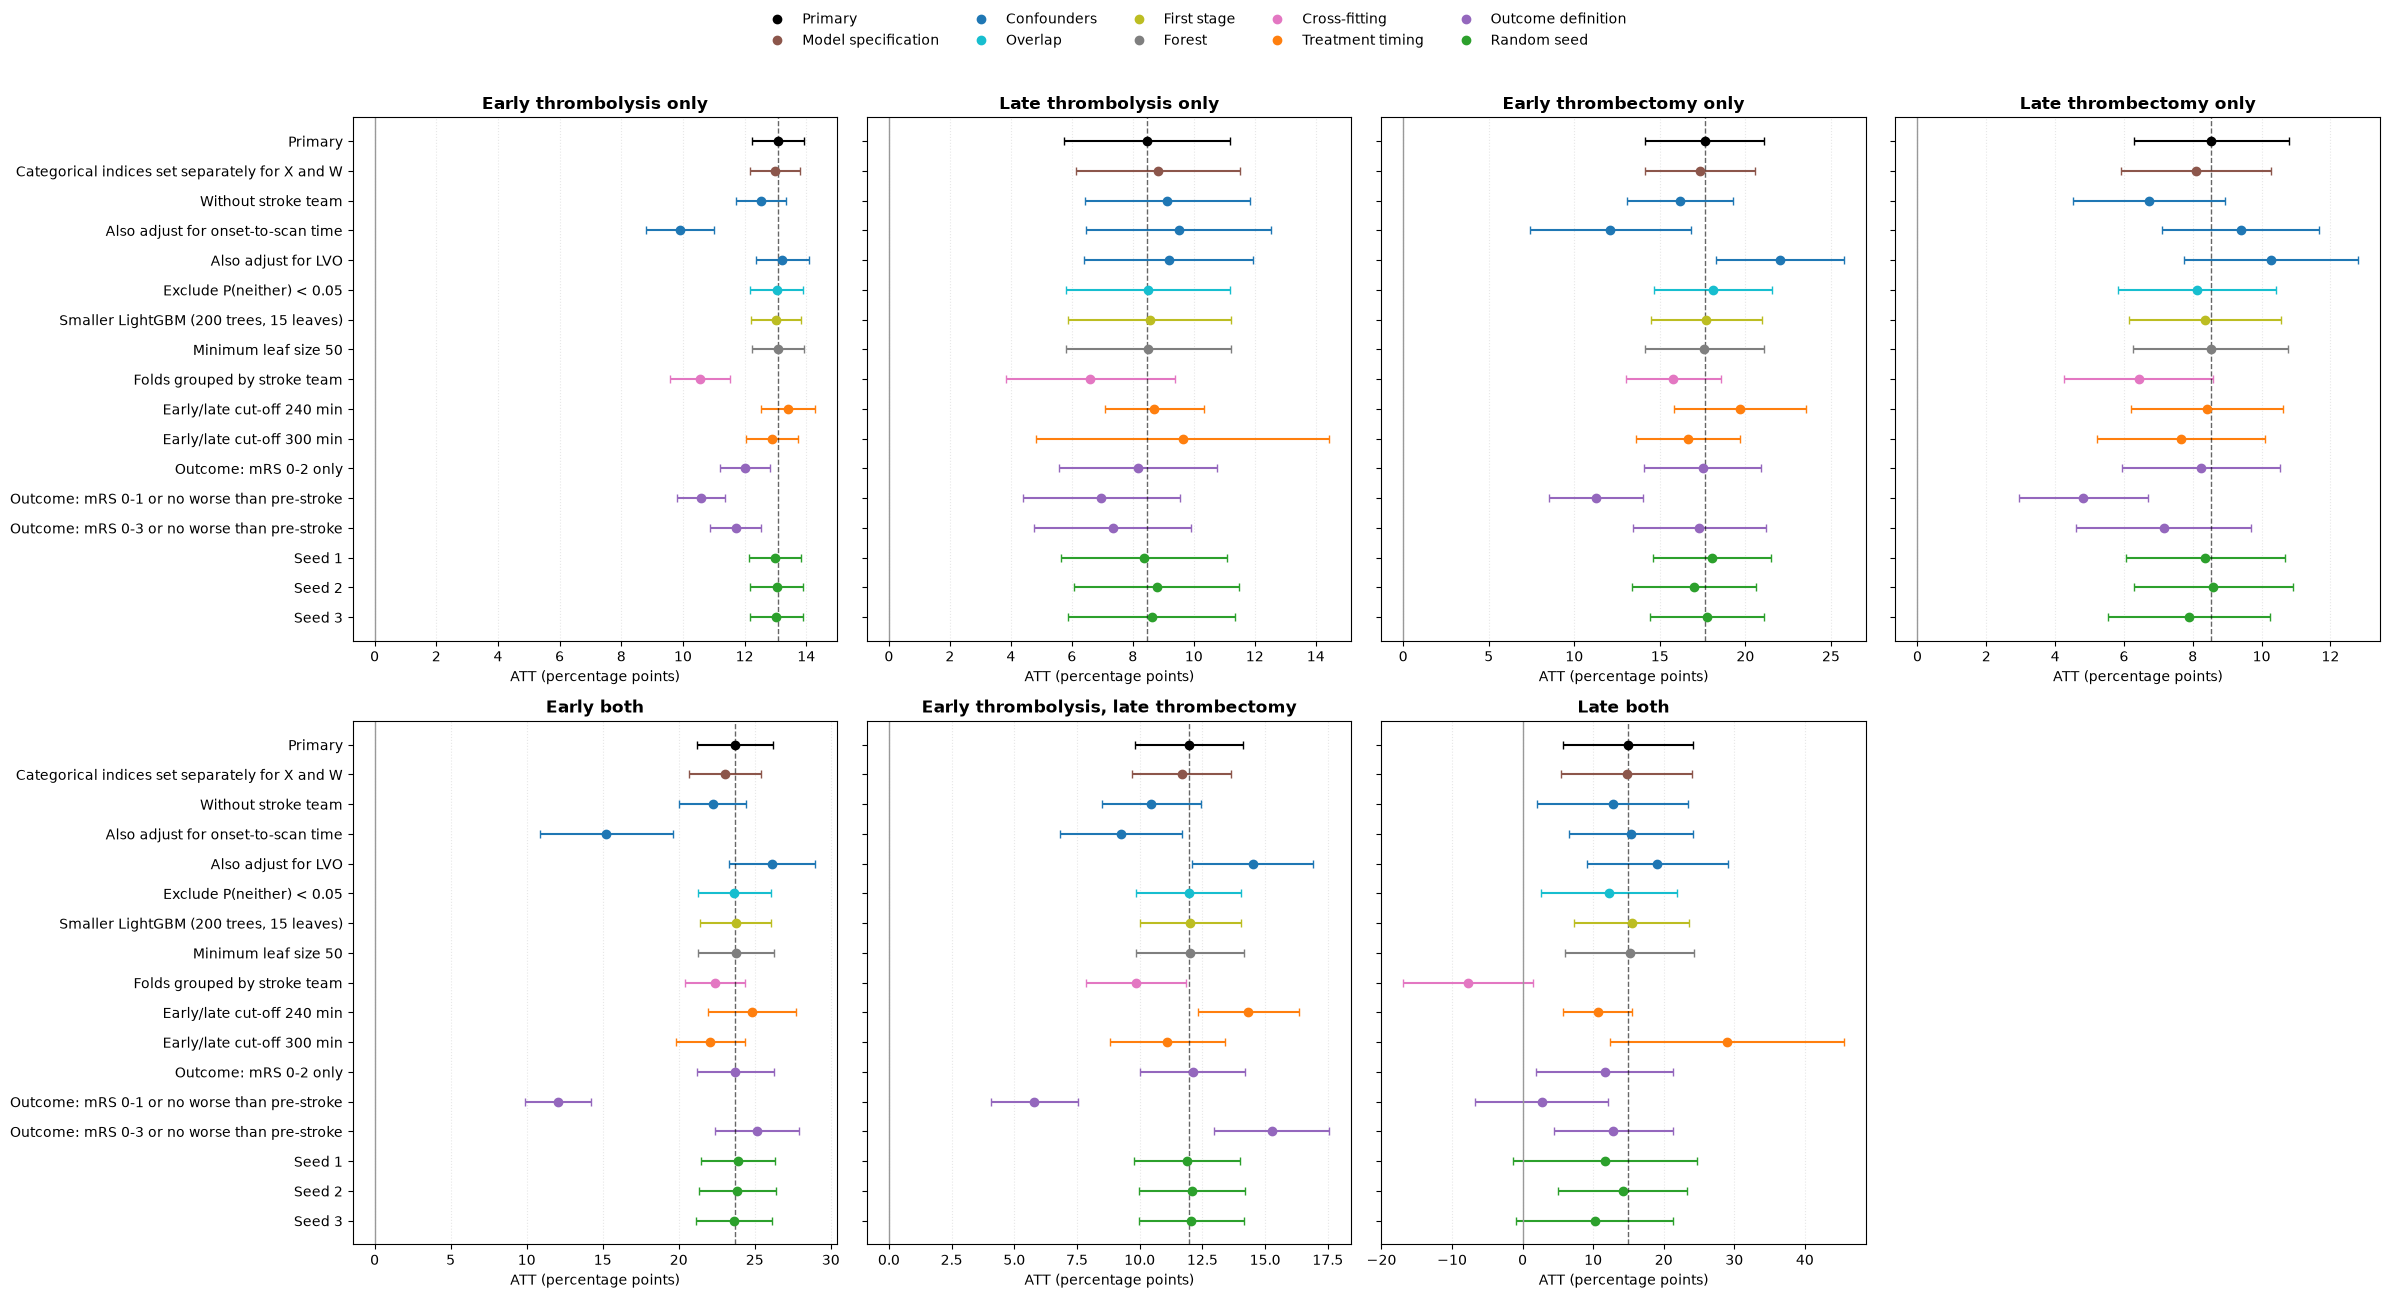

In [20]:
category_colours = {
    "Primary": "black", "Model specification": "#8c564b", "Confounders": "#1f77b4", "Overlap": "#17becf",
    "First stage": "#bcbd22", "Forest": "#7f7f7f", "Cross-fitting": "#e377c2",
    "Treatment timing": "#ff7f0e", "Outcome definition": "#9467bd", "Random seed": "#2ca02c",
}
fig, axes = plt.subplots(2, 4, figsize=(24, 13), sharey=True)
y_pos = {a: i for i, a in enumerate(analysis_order[::-1])}
for ax, group in zip(axes.flat, GROUP_ORDER):
    df = sensitivity_df[sensitivity_df["treatment_group"] == group]
    for _, r in df.iterrows():
        colour = category_colours[r["category"]]
        ax.errorbar(100 * r["att"], y_pos[r["analysis"]],
                    xerr=[[100 * (r["att"] - r["att_ci_lower"])], [100 * (r["att_ci_upper"] - r["att"])]],
                    fmt="o", color=colour, ecolor=colour, capsize=3, markersize=6)
    ax.axvline(100 * df.loc[df["analysis"] == "Primary", "att"].iloc[0], color="black", linestyle="--", lw=1, alpha=0.6)
    ax.axvline(0, color="0.6", lw=1)
    ax.set_title(GROUP_LABELS[group].replace("\n", " "), fontweight="bold")
    ax.set_xlabel("ATT (percentage points)")
    ax.grid(axis="x", alpha=0.3, linestyle=":")
axes.flat[-1].axis("off")
axes[0, 0].set_yticks(list(y_pos.values()))
axes[0, 0].set_yticklabels(list(y_pos.keys()))
for ax in axes[:, 0]:
    ax.tick_params(labelleft=True)
handles = [plt.Line2D([], [], marker="o", color=c, linestyle="", label=k) for k, c in category_colours.items()]
fig.legend(handles=handles, loc="upper center", ncol=5, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig(f"{OUTPUT_DIR}/{prefix}_sensitivity.png", dpi=300)
plt.show()

**Results.** The plot shows the same pattern as the table: the model-setting analyses cluster around the primary estimate, adjusting for onset-to-scan time shifts the early strategies to the left, and late both has wide CIs, with the team-grouped estimate below zero.

### E-values for unmeasured confounding

The E-value is the minimum strength of association, on the risk-ratio scale, that an unmeasured confounder would need with **both** treatment and outcome (beyond those adjusted for) to fully explain away the effect (VanderWeele and Ding, *Ann Intern Med* 2017;167:268–274).

The ATT is a risk difference. To turn it into a risk ratio, the treated patients' observed good-outcome proportion (p₁) is compared with their estimated proportion had they not been treated, p₀ = p₁ − ATT. The same is done for the CI limit closest to no effect. This conversion is approximate.

In [21]:
def e_value(rr):
    rr = np.asarray(rr, dtype=float)
    rr = np.where(rr < 1, 1 / rr, rr)
    return rr + np.sqrt(rr * (rr - 1))

ev = effects[["treatment_group", "n", "att", "att_ci_lower", "att_ci_upper"]].copy()
ev["p_treated"] = [y[data["treatment_group"].to_numpy() == g].mean() for g in ev["treatment_group"]]
ev["risk_ratio"] = ev["p_treated"] / (ev["p_treated"] - ev["att"])
closest = np.where(ev["att"] >= 0, ev["att_ci_lower"], ev["att_ci_upper"])
crosses_null = (ev["att_ci_lower"] <= 0) & (ev["att_ci_upper"] >= 0)
ev["e_value"] = e_value(ev["risk_ratio"])
ev["e_value_ci"] = np.where(crosses_null, 1.0, e_value(ev["p_treated"] / (ev["p_treated"] - closest)))
ev.to_csv(f"{OUTPUT_DIR}/{prefix}_e_values.csv", index=False)
ev.round(3)

,treatment_group,n,att,att_ci_lower,att_ci_upper,p_treated,risk_ratio,e_value,e_value_ci
0,early_thrombolysis_only,27675,0.131,0.122,0.139,0.490,1.364,2.069,1.999
1,late_thrombolysis_only,1189,0.085,0.057,0.112,0.472,1.219,1.735,1.536
2,early_thrombectomy_only,1107,0.176,0.141,0.211,0.388,1.830,3.062,2.520
3,late_thrombectomy_only,1876,0.085,0.063,0.108,0.336,1.341,2.017,1.762
4,early_both,2307,0.237,0.212,0.262,0.463,2.048,3.513,3.094
5,early_thrombolysis_late_thrombectomy,2714,0.120,0.098,0.141,0.372,1.474,2.310,2.057
6,late_both,141,0.149,0.057,0.241,0.440,1.513,2.394,1.563


**Results.**

* **E-values for the point estimates** range from 1.74 (late thrombolysis only) to 3.51 (early both). Early thrombectomy only is 3.06, early thrombolysis only 2.07 and late thrombectomy only 2.02.
* **E-values for the CI limits** range from 1.54 (late thrombolysis only) to 3.09 (early both).

**Discussion.** To explain away the early-both effect, an unmeasured confounder would need a risk ratio of at least about 3.1 with both treatment and good outcome, beyond everything already adjusted for. That is a strong confounder. The late-strategy effects could be explained away by weaker confounding (E-values for the CI limit 1.54 to 1.76).

### Sensitivity to unmeasured confounding: sensemakr

Cinelli and Hazlett's omitted variable bias framework describes the strength of an unmeasured confounder by its partial R², the share of the remaining (residual) variance of treatment and of outcome that it explains. It gives:

* **Robustness value RV_q** (q = 1): the minimum partial R² that a confounder would need with *both* treatment and outcome to reduce the estimate to zero.
* **RV_q,alpha**: the same, to make the 95% confidence interval include zero.
* **Partial R² of treatment with outcome**: an extreme-scenario bound. A confounder that explained all the remaining variation in outcome would still need at least this partial R² with treatment to remove the effect.
* **Benchmark bounds**: the adjusted estimate (with 95% CI) if a confounder were 1, 2 or 3 times as strongly associated with treatment and with outcome as an observed covariate.

The framework applies to linear regression, so it cannot be applied to the causal forest itself. For each strategy, a linear probability model is fitted to the patients who received it and all untreated patients, adjusting for the same confounders as the forest's first-stage models (W): good outcome ~ treated + W, with stroke team, ethnicity and year as indicator variables. The linear model is a simpler stand-in for the causal forest: it has no non-linear effects or interactions, and its predictions are not constrained to lie between 0 and 1. Benchmarks are pre-stroke mRS, NIHSS and age.

The first cell implements the formulas of the sensemakr package directly, because the Python package (PySensemakr 0.0.8) is not compatible with pandas 3; the implementation reproduces the package's published Darfur example (estimate, robustness values and benchmark bounds). The second cell fits the models and the third draws the sensitivity contours.

Cinelli C, Hazlett C. Making sense of sensitivity: extending omitted variable bias. *J R Stat Soc Series B* 2020;82:39–67.

In [22]:
from scipy import stats as _stats
import statsmodels.api as _sm


def sensemakr_analysis(model, treatment, benchmarks, kd=(1, 2, 3), q=1.0, alpha=0.05):
    """Cinelli & Hazlett (2020) omitted-variable-bias sensitivity analysis for one OLS coefficient.

    Implements the formulas of the sensemakr package directly (the PySensemakr package is not
    compatible with pandas 3). Returns a one-row DataFrame of sensitivity statistics and a
    DataFrame of bounds: the adjusted estimate if an unobserved confounder were kd times as
    strongly associated with treatment and with outcome as each benchmark covariate.
    """
    est, se, t = model.params[treatment], model.bse[treatment], model.tvalues[treatment]
    dof = model.df_resid
    t_crit = _stats.t.ppf(1 - alpha / 2, dof - 1)

    # Partial R2 of treatment with outcome, and robustness values
    r2yd_x = t**2 / (t**2 + dof)
    f_q = q * abs(t) / np.sqrt(dof)
    rv_q = 0.5 * (np.sqrt(f_q**4 + 4 * f_q**2) - f_q**2)
    f_crit = t_crit / np.sqrt(dof - 1)
    f_qa = f_q - f_crit
    if f_qa < 0:
        rv_qa = 0.0
    elif f_q > 1 / f_crit:  # extreme case (very large t), as in the sensemakr package
        rv_qa = (f_q**2 - f_crit**2) / (1 + f_q**2)
    else:
        rv_qa = 0.5 * (np.sqrt(f_qa**4 + 4 * f_qa**2) - f_qa**2)
    sens_stats = pd.DataFrame([{
        "estimate": est, "se": se, "t": t, "dof": dof, "t_crit": t_crit,
        "r2yd_x": r2yd_x, "rv_q": rv_q, "rv_qa": rv_qa,
    }])

    # Benchmark bounds: partial R2 of each benchmark with treatment (given other covariates)
    # and with outcome (given treatment and other covariates)
    exog = pd.DataFrame(model.model.exog, columns=model.model.exog_names)
    treatment_model = _sm.OLS(exog[treatment], exog.drop(columns=treatment)).fit()
    rows = []
    for b in benchmarks:
        t_dx = treatment_model.tvalues[b]
        r2dxj_x = t_dx**2 / (t_dx**2 + treatment_model.df_resid)
        r2yxj_dx = model.tvalues[b]**2 / (model.tvalues[b]**2 + dof)
        for k in kd:
            row = {"benchmark": b, "kd": k}
            if k * r2dxj_x >= 1:
                rows.append(row)
                continue
            r2dz_x = k * r2dxj_x / (1 - r2dxj_x)
            r2zxj_xd = k * r2dxj_x**2 / ((1 - k * r2dxj_x) * (1 - r2dxj_x))
            r2yz_dx = min(1.0, ((np.sqrt(k) + np.sqrt(r2zxj_xd)) / np.sqrt(1 - r2zxj_xd))**2
                          * r2yxj_dx / (1 - r2yxj_dx))
            bias = se * np.sqrt(r2yz_dx * r2dz_x / (1 - r2dz_x) * dof)
            adj_est = np.sign(est) * (abs(est) - bias)
            adj_se = se * np.sqrt((1 - r2yz_dx) / (1 - r2dz_x) * dof / (dof - 1))
            row.update({"r2dz_x": r2dz_x, "r2yz_dx": r2yz_dx, "adjusted_estimate": adj_est,
                        "adjusted_ci_lower": adj_est - t_crit * adj_se,
                        "adjusted_ci_upper": adj_est + t_crit * adj_se})
            rows.append(row)
    return sens_stats, pd.DataFrame(rows)


def adjusted_estimate_grid(est, se, dof, r2dz_x, r2yz_dx):
    """Adjusted estimate (bias towards zero) over a grid of confounder partial R2 values."""
    bias = se * np.sqrt(r2yz_dx * r2dz_x / (1 - r2dz_x) * dof)
    return np.sign(est) * (abs(est) - bias)


BENCHMARK_MARKERS = {"prior_disability": "o", "stroke_severity": "s", "age": "^", "onset_to_scan_time": "D"}
BENCHMARK_NAMES = {"prior_disability": "pre-stroke mRS", "stroke_severity": "NIHSS", "age": "age",
                   "onset_to_scan_time": "onset-to-scan time"}


def plot_sensemakr_contours(sens_stats, sens_bounds, labels, filename, scale=100, unit="percentage points"):
    """One contour plot per treatment strategy: adjusted estimate against the partial R2 of a
    hypothetical confounder with treatment (x) and with outcome (y). The red dashed line is
    where the estimate would fall to zero; markers show confounders 1x, 2x and 3x as strong
    as each benchmark covariate."""
    strategies = list(sens_stats.index)
    ncols = 4
    nrows = int(np.ceil(len(strategies) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.9 * nrows), squeeze=False)
    for ax, strategy in zip(axes.flat, strategies):
        st = sens_stats.loc[strategy]
        b = sens_bounds[(sens_bounds["treatment_group"] == strategy)].dropna(subset=["r2dz_x"])
        lim = max(0.05, 1.2 * max(b["r2dz_x"].max(), b["r2yz_dx"].max(), st["rv_q"]))
        lim = min(lim, 0.95)
        grid = np.linspace(0, lim, 201)
        gx, gy = np.meshgrid(grid, grid)
        z = scale * adjusted_estimate_grid(st["estimate"], st["se"], st["dof"], gx, gy)
        cs = ax.contour(gx, gy, z, levels=8, colors="grey", linewidths=0.7)
        ax.clabel(cs, fontsize=7, fmt="%.0f")
        ax.contour(gx, gy, z, levels=[0], colors="red", linestyles="--", linewidths=1.3)
        for _, r in b.iterrows():
            ax.plot(r["r2dz_x"], r["r2yz_dx"], BENCHMARK_MARKERS.get(r["benchmark"], "x"),
                    color="black", ms=4 + r["kd"])
        ax.plot(0, 0, "*", color="tab:blue", ms=9)
        ax.set_xlim(0, lim)
        ax.set_ylim(0, lim)
        ax.set_title(labels.get(strategy, strategy).replace("\n", " "), fontsize=10)
        ax.set_xlabel("Partial R² of confounder with treatment", fontsize=8)
        ax.set_ylabel("Partial R² of confounder with outcome", fontsize=8)
        ax.tick_params(labelsize=7)
    for ax in axes.flat[len(strategies):]:
        ax.axis("off")
    handles = [plt.Line2D([], [], color="red", linestyle="--", label="Adjusted estimate = 0"),
               plt.Line2D([], [], marker="*", color="tab:blue", linestyle="", label="Unadjusted estimate")]
    used = sorted(set(sens_bounds["benchmark"]), key=list(BENCHMARK_MARKERS).index)
    handles += [plt.Line2D([], [], marker=BENCHMARK_MARKERS.get(b, "x"), color="black", linestyle="",
                           label=f"1x, 2x, 3x {BENCHMARK_NAMES.get(b, b)}") for b in used]
    fig.legend(handles=handles, loc="lower right", fontsize=8, frameon=False)
    fig.suptitle(f"Sensitivity contours: adjusted effect ({unit})", fontsize=12)
    fig.tight_layout()
    fig.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()


def format_sensemakr_tables(sens_stats, sens_bounds, labels, scale=100, decimals=1):
    """Publication tables: robustness statistics, and adjusted estimates for each benchmark."""
    fmt = lambda x: f"{scale * x:.{decimals}f}"
    summary = pd.DataFrame({
        "n": sens_stats["n"].astype(int).to_numpy(),
        "estimate (95% CI)": [f"{fmt(r.estimate)} ({fmt(r.estimate - r.t_crit * r.se)}, {fmt(r.estimate + r.t_crit * r.se)})"
                              for r in sens_stats.itertuples()],
        "partial R2 of treatment (%)": (100 * sens_stats["r2yd_x"]).round(2).to_numpy(),
        "RV_q (%)": (100 * sens_stats["rv_q"]).round(1).to_numpy(),
        "RV_q,alpha (%)": (100 * sens_stats["rv_qa"]).round(1).to_numpy(),
    }, index=[labels.get(s, s).replace("\n", " ") for s in sens_stats.index])
    b = sens_bounds.copy()
    b["adjusted (95% CI)"] = [
        "" if pd.isna(r.adjusted_estimate) else
        f"{fmt(r.adjusted_estimate)} ({fmt(r.adjusted_ci_lower)}, {fmt(r.adjusted_ci_upper)})"
        for r in b.itertuples()]
    b["bound"] = b["kd"].astype(str) + "x " + b["benchmark"].map(lambda x: BENCHMARK_NAMES.get(x, x))
    bounds_table = b.pivot(index="treatment_group", columns="bound", values="adjusted (95% CI)")
    bounds_table = bounds_table.reindex(index=list(sens_stats.index),
                                        columns=list(dict.fromkeys(b["bound"])))
    bounds_table.index = [labels.get(s, s).replace("\n", " ") for s in bounds_table.index]
    return summary, bounds_table

In [23]:
# Linear probability model for each strategy vs neither, adjusting for the causal
# forest's first-stage confounders (W).
SENS_BENCHMARKS = ["prior_disability", "stroke_severity", "age"]
SENS_CATEGORICAL = ["stroke_team", "ethnicity", "year"]

y_all = ((data["discharge_disability"] <= MRS_TARGET)
         | (data["discharge_disability"] <= data["prior_disability"])).astype(float)
covariates = pd.get_dummies(
    data[W_FEATURES].astype({c: str for c in SENS_CATEGORICAL}),
    columns=SENS_CATEGORICAL,
    drop_first=True,
    dtype=float,
)

sens_rows, sens_bound_rows = [], []
for strategy in GROUP_ORDER:
    in_group = data["treatment_group"].isin([strategy, CONTROL_GROUP]).to_numpy()
    df = covariates[in_group].assign(
        treated=(data["treatment_group"][in_group] == strategy).astype(float).to_numpy(),
        y=y_all[in_group].to_numpy(),
    )
    X = df.drop(columns="y")
    X = X.loc[:, X.std() > 0]  # Drop indicator columns constant within this subset
    lpm = _sm.OLS(df["y"], _sm.add_constant(X, has_constant="add")).fit()

    stats_row, bounds = sensemakr_analysis(lpm, "treated", SENS_BENCHMARKS)
    sens_rows.append(stats_row.assign(treatment_group=strategy, n=len(df)))
    sens_bound_rows.append(bounds.assign(treatment_group=strategy))

sensemakr_stats = pd.concat(sens_rows).set_index("treatment_group")
sensemakr_bounds = pd.concat(sens_bound_rows, ignore_index=True)
sensemakr_stats.to_csv(f"{OUTPUT_DIR}/{prefix}_sensemakr.csv")
sensemakr_bounds.to_csv(f"{OUTPUT_DIR}/{prefix}_sensemakr_bounds.csv", index=False)

sensemakr_summary, sensemakr_bounds_table = format_sensemakr_tables(
    sensemakr_stats, sensemakr_bounds, GROUP_LABELS
)
display(sensemakr_summary)
display(sensemakr_bounds_table)

,n,estimate (95% CI),partial R2 of treatment (%),RV_q (%),"RV_q,alpha (%)"
Early thrombolysis only,65277,"11.2 (10.4, 11.9)",1.19,10.4,9.7
Late thrombolysis only,38791,"8.9 (6.3, 11.5)",0.11,3.3,2.3
Early thrombectomy only,38709,"15.5 (12.7, 18.3)",0.30,5.3,4.4
Late thrombectomy only,39478,"6.5 (4.3, 8.7)",0.09,2.9,2.0
Early both,39909,"21.1 (19.0, 23.1)",1.00,9.5,8.7
"Early thrombolysis, late thrombectomy",40316,"10.2 (8.3, 12.1)",0.28,5.1,4.2
Late both,37743,"12.8 (5.3, 20.3)",0.03,1.7,0.7


bound,1x pre-stroke mRS,2x pre-stroke mRS,3x pre-stroke mRS,1x NIHSS,2x NIHSS,3x NIHSS,1x age,2x age,3x age
Early thrombolysis only,"7.8 (7.0, 8.6)","4.1 (3.3, 5.0)","0.2 (-0.6, 1.1)","9.3 (8.5, 10.0)","7.4 (6.7, 8.1)","5.5 (4.9, 6.2)","10.6 (9.8, 11.3)","10.0 (9.2, 10.7)","9.4 (8.6, 10.1)"
Late thrombolysis only,"5.1 (2.5, 7.7)","1.2 (-1.4, 3.7)","-2.7 (-5.2, -0.2)","8.2 (5.6, 10.7)","7.4 (5.0, 9.8)","6.7 (4.4, 8.9)","8.1 (5.4, 10.7)","7.2 (4.6, 9.8)","6.3 (3.8, 8.9)"
Early thrombectomy only,"8.4 (5.6, 11.2)","1.2 (-1.6, 4.0)","-6.2 (-8.9, -3.4)","1.3 (-1.4, 4.0)","-13.2 (-15.8, -10.6)","-28.2 (-30.6, -25.7)","13.2 (10.5, 16.0)","11.0 (8.2, 13.7)","8.7 (6.0, 11.4)"
Late thrombectomy only,"-0.3 (-2.4, 1.9)","-7.2 (-9.4, -5.1)","-14.4 (-16.5, -12.2)","-3.8 (-5.9, -1.8)","-14.4 (-16.4, -12.4)","-25.2 (-27.1, -23.4)","4.1 (2.0, 6.3)","1.7 (-0.4, 3.9)","-0.7 (-2.8, 1.4)"
Early both,"12.6 (10.5, 14.7)","3.7 (1.6, 5.8)","-5.7 (-7.8, -3.6)","6.4 (4.4, 8.4)","-9.0 (-10.9, -7.1)","-25.2 (-27.1, -23.4)","18.3 (16.2, 20.3)","15.5 (13.5, 17.5)","12.6 (10.6, 14.6)"
"Early thrombolysis, late thrombectomy","2.4 (0.5, 4.3)","-5.8 (-7.7, -3.9)","-14.4 (-16.3, -12.5)","-1.8 (-3.6, 0.0)","-14.2 (-16.0, -12.5)","-27.2 (-28.9, -25.6)","7.4 (5.6, 9.3)","4.7 (2.8, 6.5)","1.9 (0.1, 3.7)"
Late both,"5.7 (-1.7, 13.0)","-1.5 (-8.7, 5.8)","-8.6 (-15.7, -1.5)","3.8 (-3.3, 10.9)","-5.2 (-11.9, 1.5)","-14.3 (-20.5, -8.0)","10.7 (3.3, 18.0)","8.5 (1.3, 15.8)","6.4 (-0.8, 13.6)"


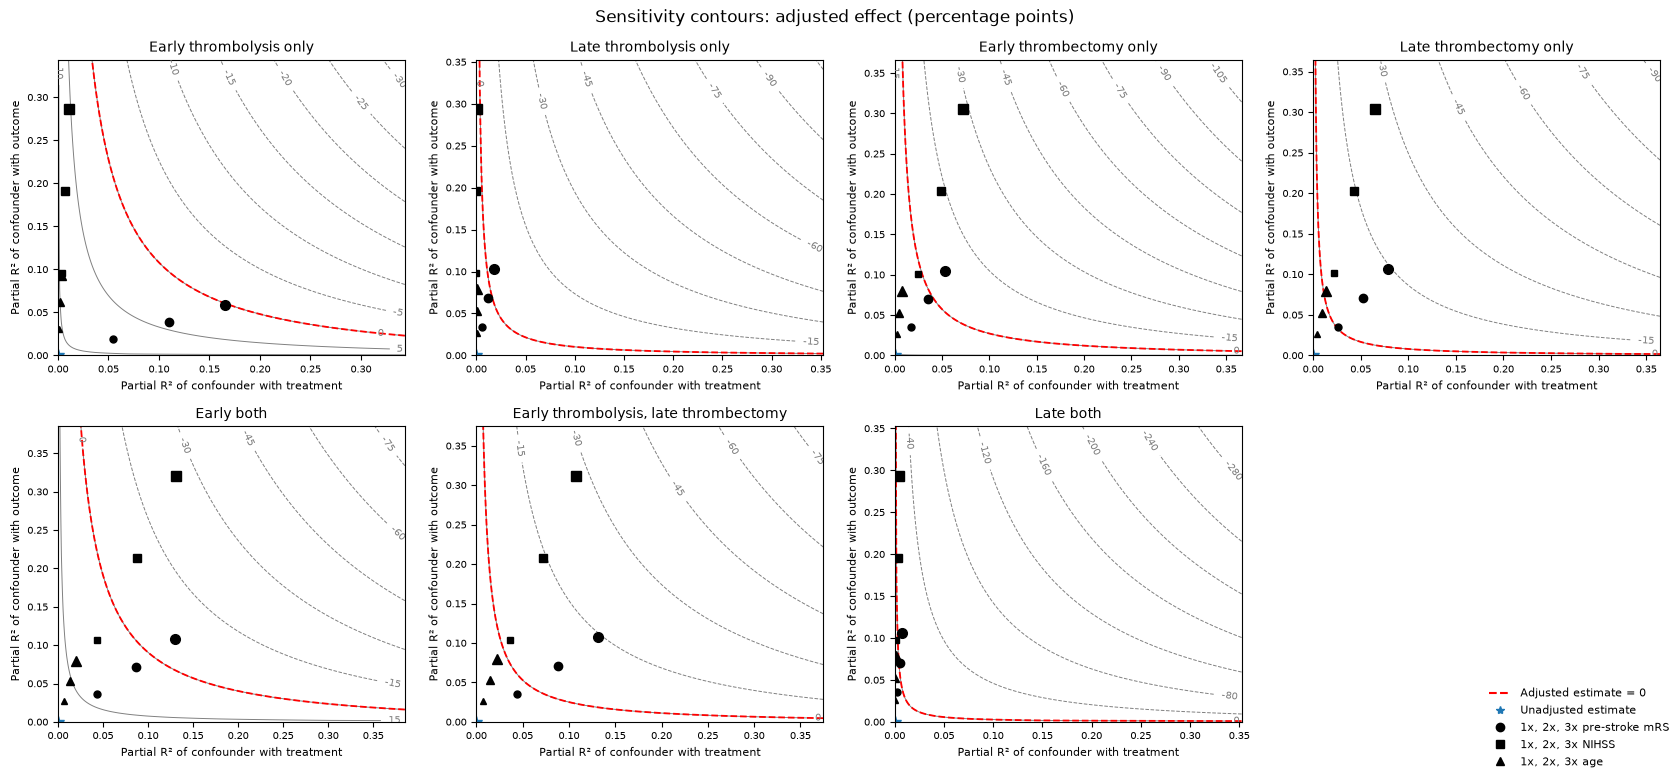

In [24]:
plot_sensemakr_contours(sensemakr_stats, sensemakr_bounds, GROUP_LABELS,
                        f"{OUTPUT_DIR}/{prefix}_sensemakr_contours.png")

**Results.**

* **The linear model's estimates are 1.8 to 2.6 points below the causal forest ATT** for every strategy except late thrombolysis only (early both +21.1 vs +23.7 percentage points; early thrombectomy only +15.5 vs +17.6; early thrombolysis only +11.2 vs +13.1; late thrombolysis only +8.9 vs +8.5), so the two approaches agree on the pattern of effects.
* **Robustness values:** RV_q from 10.4% (early thrombolysis only) and 9.5% (early both) down to 2.9% (late thrombectomy only) and 1.7% (late both); RV_q,alpha from 0.7% to 9.7%.
* **Benchmarks:**
  * **Age:** a confounder as strong as age, even three times as strong, would leave every effect positive except late thrombectomy only (3× age: −0.7 percentage points).
  * **Pre-stroke mRS:** a confounder as strong as pre-stroke mRS would remove the effect of late thrombectomy only (−0.3) and most of early thrombolysis with late thrombectomy (2.4), and roughly halve early thrombectomy only (8.4) and early both (12.6).
  * **NIHSS:** a confounder as strong as NIHSS would remove most or all of the thrombectomy effects (early thrombectomy only 1.3, early both 6.4, late thrombectomy only −3.8, early thrombolysis with late thrombectomy −1.8), but not the thrombolysis-only effects (early 9.3, late 8.2), because NIHSS is only weakly related to receiving thrombolysis alone.
* **Contour plot:** each panel shows the adjusted estimate for a hypothetical confounder with the partial R² with treatment (horizontal axis) and with outcome (vertical axis). The red dashed line is where the effect would fall to zero; solid grey lines show smaller positive effects and grey dashed lines negative effects. Far contours are linear extrapolations with no meaning on the probability scale.

**Discussion.** The thrombolysis estimates are robust to unmeasured confounding as strong as any measured covariate. The thrombectomy estimates would be overturned by an unmeasured confounder as strong as stroke severity or pre-stroke disability, beyond those already adjusted for. LVO status and imaging findings are the most plausible such confounders.

### Leave-one-out analysis of the main confounders

Each of the three strongest measured confounders (NIHSS, age and pre-stroke mRS) is removed in turn from both the effect modifiers (X) and the first-stage confounders (W), and the causal forest and doubly robust ATT are re-estimated. Leaving out a measured confounder is a deliberate misspecification: the change in the ATT shows how much each result depends on adjusting for that confounder, and so how much bias an unmeasured confounder of similar strength, acting in the same direction, could cause. Each refit takes about as long as the primary model.

In [25]:
# Leave-one-out sensitivity analysis: remove each main confounder from X and W in turn
LOO_FEATURES = {
    "Without NIHSS": "stroke_severity",
    "Without age": "age",
    "Without pre-stroke mRS": "prior_disability",
}
primary_effects = effects if "effects" in globals() else pd.read_csv(f"{OUTPUT_DIR}/{prefix}_effects.csv")
loo_results = [primary_effects.assign(analysis="Primary")]
for label, feature in LOO_FEATURES.items():
    est_loo, X_loo, _, y_loo, arm_loo, seconds = fit_causal_forest(
        data,
        x_features=[f for f in X_FEATURES if f != feature],
        w_features=[f for f in W_FEATURES if f != feature],
    )
    loo_results.append(dr_effects(est_loo, X_loo, y_loo, arm_loo, label, "Leave one out"))
    print(f"{label}: {seconds / 60:.1f} min")

loo_df = pd.concat(loo_results, ignore_index=True)
primary_att = loo_df[loo_df["analysis"] == "Primary"].set_index("treatment_group")["att"]
loo_df["change_pp"] = 100 * (loo_df["att"] - loo_df["treatment_group"].map(primary_att))
loo_df["att_pp"] = [f"{100 * a:.1f} ({100 * l:.1f}, {100 * u:.1f})"
                    for a, l, u in loo_df[["att", "att_ci_lower", "att_ci_upper"]].to_numpy()]
loo_df.to_csv(f"{OUTPUT_DIR}/{prefix}_leave_one_out.csv", index=False)

loo_columns = ["Primary", *LOO_FEATURES]
for values, title in [("att_pp", "Doubly robust ATT, percentage points (95% CI)"),
                      ("change_pp", "Change from the primary estimate, percentage points")]:
    print(title)
    display(loo_df.pivot(index="treatment_group", columns="analysis", values=values)
            .reindex(index=GROUP_ORDER, columns=loo_columns).round(1))

Without NIHSS: 3.5 min


Without age: 3.4 min


Without pre-stroke mRS: 3.5 min
Doubly robust ATT, percentage points (95% CI)


analysis,Primary,Without NIHSS,Without age,Without pre-stroke mRS
treatment_group,,,,
early_thrombolysis_only,"13.1 (12.2, 13.9)","10.2 (9.3, 11.1)","13.5 (12.7, 14.4)","9.6 (8.7, 10.4)"
late_thrombolysis_only,"8.5 (5.7, 11.2)","7.1 (4.3, 10.0)","9.1 (6.4, 11.9)","5.5 (2.7, 8.2)"
early_thrombectomy_only,"17.6 (14.1, 21.1)","-0.6 (-4.0, 2.7)","19.3 (16.0, 22.6)","11.6 (8.4, 14.8)"
late_thrombectomy_only,"8.5 (6.3, 10.8)","-5.7 (-8.0, -3.3)","10.3 (8.1, 12.6)","3.2 (0.9, 5.5)"
early_both,"23.7 (21.2, 26.2)","4.2 (1.8, 6.7)","25.3 (22.8, 27.8)","17.5 (15.1, 19.9)"
early_thrombolysis_late_thrombectomy,"12.0 (9.8, 14.1)","-4.0 (-6.1, -1.9)","14.1 (12.0, 16.2)","6.5 (4.4, 8.6)"
late_both,"14.9 (5.7, 24.1)","-1.2 (-11.9, 9.4)","15.9 (6.0, 25.7)","10.5 (2.0, 19.1)"


Change from the primary estimate, percentage points


analysis,Primary,Without NIHSS,Without age,Without pre-stroke mRS
treatment_group,,,,
early_thrombolysis_only,0.0,-2.9,0.5,-3.5
late_thrombolysis_only,0.0,-1.3,0.7,-3.0
early_thrombectomy_only,0.0,-18.3,1.7,-6.0
late_thrombectomy_only,0.0,-14.2,1.8,-5.3
early_both,0.0,-19.5,1.6,-6.2
early_thrombolysis_late_thrombectomy,0.0,-15.9,2.1,-5.5
late_both,0.0,-16.1,1.0,-4.4


**Results.**

* **Leaving out age** increases the ATTs by 0.5 to 2.1 percentage points.
* **Leaving out pre-stroke mRS** reduces them by 3.0 to 6.2 points (for example late thrombectomy only 8.5 → 3.2; early thrombolysis only 13.1 → 9.6).
* **Leaving out NIHSS** changes the thrombolysis-only ATTs by −2.9 and −1.3 points but reduces every thrombectomy-based ATT by 14 to 20 points, to between −5.7 and +4.2 (for example early both 23.7 → 4.2; early thrombectomy only 17.6 → −0.6).

**Discussion.** Patients selected for thrombectomy have more severe strokes, and so a worse prognosis, than untreated patients. Without NIHSS the model cannot separate the effect of thrombectomy from that of severity. The thrombectomy results therefore depend heavily on adjustment for stroke severity, in agreement with the sensemakr benchmarks.

# 10. Observed outcomes by treatment strategy

Unadjusted number and percentage with a good outcome, in-hospital deaths and length of stay (median, IQR) for the analysed cohort, printed as LaTeX rows for the paper's supplementary table (TARGET items 10 and 12). Counts below 10 are suppressed.

In [26]:
# Observed outcome, in-hospital death and length of stay by treatment strategy,
# printed as LaTeX rows for Supplementary Table "tab:observed_outcomes" (TARGET items 10 and 12).
# Counts below 10 are suppressed, as elsewhere in the paper.

import pandas as pd

LABELS = {
    "neither": "No treatment",
    "early_thrombolysis_only": "Early IVT only",
    "late_thrombolysis_only": "Late IVT only",
    "early_thrombectomy_only": "Early MT only",
    "late_thrombectomy_only": "Late MT only",
    "early_both": "Early IVT + early MT",
    "early_thrombolysis_late_thrombectomy": "Early IVT + late MT",
    "late_both": "Late IVT + late MT",
}


def count_pct(k, n):
    """'k (p%)', or '<10' if the count is below 10."""
    if k < 10:
        return "$<$10"
    return f"{k:,} ({100 * k / n:.1f}\\%)"


def observed_outcome_rows(cohort, outcome_source, group_order):
    """
    cohort: analysed data frame with 'treatment_group', 'discharge_disability'
            and 'prior_disability'.
    outcome_source: data frame holding 'length_of_stay' and 'death' for the same
            patients (same index); for the S-learner this is the cohort itself.
    group_order: treatment groups in the order to print.
    """
    extra = outcome_source.loc[cohort.index, ["length_of_stay", "death"]]
    mrs = cohort["discharge_disability"]
    good = (mrs <= 2) | (mrs <= cohort["prior_disability"])
    table = pd.DataFrame({
        "group": cohort["treatment_group"].astype(str),
        "good": good.astype(int),
        "death": pd.to_numeric(extra["death"], errors="coerce"),
        "los": pd.to_numeric(extra["length_of_stay"], errors="coerce"),
    })
    print(f"% {len(table):,} patients; missing death: {table['death'].isna().sum()}, "
          f"missing length of stay: {table['los'].isna().sum()}")
    for group in group_order:
        rows = table[table["group"] == group]
        n = len(rows)
        if n == 0:
            continue
        good_k = int(rows["good"].sum())
        death_k = int((rows["death"] == 1).sum())
        q1, med, q3 = rows["los"].quantile([0.25, 0.5, 0.75])
        print(f"{LABELS.get(group, group)} & {n:,} & {count_pct(good_k, n)} & "
              f"{count_pct(death_k, n)} & {med:.0f} ({q1:.0f}--{q3:.0f}) \\\\")


# Causal forest cohort (complete cases): data holds model columns only, so take outcomes from raw_data
observed_outcome_rows(data, raw_data, [CONTROL_GROUP] + GROUP_ORDER)


% 74,611 patients; missing death: 0, missing length of stay: 8
No treatment & 37,602 & 14,181 (37.7\%) & 7,488 (19.9\%) & 13 (5--35) \\
Early IVT only & 27,675 & 13,555 (49.0\%) & 3,446 (12.5\%) & 8 (3--29) \\
Late IVT only & 1,189 & 561 (47.2\%) & 145 (12.2\%) & 10 (4--38) \\
Early MT only & 1,107 & 430 (38.8\%) & 178 (16.1\%) & 16 (5--45) \\
Late MT only & 1,876 & 630 (33.6\%) & 299 (15.9\%) & 21 (7--55) \\
Early IVT + early MT & 2,307 & 1,069 (46.3\%) & 246 (10.7\%) & 10 (4--36) \\
Early IVT + late MT & 2,714 & 1,010 (37.2\%) & 317 (11.7\%) & 16 (6--51) \\
Late IVT + late MT & 141 & 62 (44.0\%) & $<$10 & 30 (6--74) \\


**Results.** 37.7% of untreated patients had a good outcome, compared with 49.0% after early thrombolysis only, 47.2% after late thrombolysis only, 38.8% after early thrombectomy only, 33.6% after late thrombectomy only, 46.3% after early both, 37.2% after early thrombolysis with late thrombectomy and 44.0% after late both. In-hospital death was 19.9% in untreated patients and 10.7% to 16.1% in the treated groups. Median length of stay was 13 days (IQR 5 to 35) for untreated patients, 8 days after early thrombolysis only and 10 to 30 days in the thrombectomy groups.

**Discussion.** These are unadjusted comparisons. Thrombectomy patients have more severe strokes, so their raw good-outcome rates are lower than after thrombolysis alone; the doubly robust estimates above account for this.

# 11. Conclusions and limitations

### Conclusions

* **All strategies are associated with benefit.** After doubly robust adjustment, every thrombolysis and thrombectomy strategy is associated with a higher probability of a good outcome at discharge in the patients who received it, by about 8 to 24 percentage points (ATT +8.5 to +23.7; risk ratios 1.22 to 2.05). All 95% CIs exclude zero.
* **Timing.** Early thrombolysis plus early thrombectomy has the largest benefit (+23.7), and earlier treatment is better than later: thrombolysis only +13.1 vs +8.5, thrombectomy only +17.6 vs +8.5, and after early thrombolysis +23.7 with early vs +12.0 with late thrombectomy.
* **Model quality.** The first-stage models discriminate well (outcome AUC 0.753; treatment AUCs 0.679 to 0.906) and the outcome model is well calibrated (slope 0.94). Overlap is good for effects in the treated; whole-cohort effects (ATE) can be estimated only for early thrombolysis only (+11.5).
* **Heterogeneity.** The forest detects modest real variation in benefit for early thrombolysis only (BLP slope 0.48, *p* < 0.001) and early both (0.35, *p* = 0.003). Benefit tends to be smaller in patients aged 80 and over and with more pre-stroke disability. For the smaller strategies, individual estimates are dominated by noise.
* **Robustness.** The findings are robust to model settings, random seeds, overlap trimming, categorical encoding and the early/late cut-off. They are more sensitive to which confounders are included: additionally adjusting for onset-to-scan time lowers the early-strategy effects by 3 to 9 points (early both 15.2), and adjusting for LVO raises the thrombectomy effects. Stroke-team handling and the outcome definition change the size but not the direction of the effects, except for the small late-both group.
* **Confounding.** E-values range from 1.74 to 3.51 (1.54 to 3.09 at the CI limit). The thrombolysis-alone effects survive confounding as strong as any measured covariate and change little when NIHSS is left out. The thrombectomy-based effects are largely removed by a confounder as strong as NIHSS or by leaving NIHSS out of the model, so they depend heavily on adjustment for stroke severity.

### Limitations

* **Unmeasured confounding.** The estimates assume all important confounders are measured. Not captured: LVO status for most untreated patients, imaging findings, contraindications and reasons treatment was not given.
* **Choice of adjustment variables.** Onset-to-scan time is not adjusted for in the primary analysis, because it largely determines whether early treatment is possible. If it also captures confounding, the primary early-strategy effects are too high; adjusting for it lowers them by 3 to 9 points. The primary estimates (without it) and the sensitivity estimates (with it) can be seen as plausible upper and lower values.
* **Positivity.** Most strategies are given to a selected minority, so whole-cohort effects cannot be estimated for them, and propensities had to be clipped (at 0.01) for stable doubly robust estimates.
* **Timing of treatment and time zero.** Strategies are defined by when treatment was actually given. A patient who died or deteriorated before late treatment is counted as untreated, which can favour the late strategies.
* **Statistical details.** The AIPW confidence intervals treat the first-stage predictions as fixed and use in-sample forest estimates. Subgroup patterns have no CIs. Results for late both (141 patients) are unstable.
* **Complete data.** 67 patients with missing NIHSS are excluded.
* **Outcome at discharge.** This is not the 90-day mRS used in most trials, and it depends on length of stay and discharge arrangements.